# Imports


In [ ]:
import numpy as np
import math
import os
import scipy.stats as stats
import matplotlib.pyplot as plt
from itertools import permutations
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd
from enum import Enum
from abc import ABC, abstractmethod
import time
try:
  from google.colab import files
  from google.colab import output
  output.enable_custom_widget_manager()
except ImportError:
  pass

import plotly.express as px
import plotly.graph_objects as go

def SampleUnitInterval(size, distribution='uniform'):
  """Samples random values in [0, 1] according to the specified distribution.
  Supported distributions:
    - 'uniform': Baseline U(0, 1) (Maximum Entropy)
    - 'normal': Truncated Normal N(mu=0.5, sigma=0.22) on [0, 1] (Central clustering)
    - 'beta': Skewed Beta(alpha=2, beta=5) on [0, 1] (Right-skewed asymmetry)
  """
  if distribution == 'uniform':
    return np.random.randint(0, 101, size) / 100.0
  elif distribution == 'normal':
    a, b = (0.0 - 0.5) / 0.22, (1.0 - 0.5) / 0.22
    return np.round(stats.truncnorm.rvs(a, b, loc=0.5, scale=0.22, size=size), 2)
  elif distribution == 'beta':
    return np.round(np.random.beta(2.0, 5.0, size=size), 2)
  else:
    raise ValueError(f"Unsupported distribution: {distribution}")


In [ ]:
#@title NRFPRS from different preference relations
n = 4
tfn = np.array([[1, 0.33, 0.44, 1],
                [1, 1, 0.857, 1],
                [1, 1, 1, 1],
                [1, 0, 0.286, 1]])

ord_uv_diff = np.array([[1, 0.8, 0.2, 0.5],
                        [1, 1, 0.4, 0.7],
                        [1, 1, 1, 1],
                        [1, 1, 0.7, 1]])

oa = np.array([[1, 1, 0.33, 1],
               [0.167, 1, 0, 0.33],
               [1, 1, 1, 1],
               [0.33, 1, 0.167, 1]])

rn_fixed = np.array([[1, 1, 1, 0.86],
                    [0.86, 1, 0.86, 0.72],
                    [1, 1, 1, 0.86],
                    [1, 1, 1, 1]])

trfn = np.array([[1, 1, 1, 1],
                 [0, 1, 0.273, 0],
                 [0.182, 1, 1, 0.2],
                 [1, 1, 1, 1]])

mpr = np.array([[1, 1, 1, 1],
                [0, 1, 0.268, 0],
                [0.268, 1, 1, 0.268],
                [1, 1, 1, 1]])

# Orlovsky Techniques

In [ ]:
#@title Helper Functions for the Techniques

def NrfprIntersection(r_set, criteria_names):
  if len(r_set) == 0:
    return None
  n = r_set[0].shape[0]
  intersection = np.zeros((n, n))

  intersection_names = [[] for _ in range(n)]
  for i in range(n):
    intersection_names[i] = [set() for _ in range(n)]

  for i in range(n):
    for j in range(n):
      min_value = r_set[0][i, j]
      min_value_criteria = {criteria_names[0]} if i != j else None
      for k in range(len(r_set)):
        if math.isclose(r_set[k][i, j], min_value, abs_tol=1e-12) and min_value_criteria is not None:
          min_value_criteria.add(criteria_names[k])
        elif r_set[k][i, j] < min_value - 1e-12:
          min_value = r_set[k][i, j]
          if min_value_criteria is not None:
            min_value_criteria = {criteria_names[k]}
      intersection[i, j] = min_value
      intersection_names[i][j] = min_value_criteria

  return intersection, intersection_names

# Returns the strict preference relation P taken from the non-strict preference
# relation NR
def StrictPreferenceRelation(nr, contributing_criteria):
  n = nr.shape[0]
  p = np.zeros(nr.shape)
  dominating_criteria = [[] for _ in range(n)]
  for i in range(n):
    dominating_criteria[i] = [set() for _ in range(n)]
    dominating_criteria[i][i] = None

  for i in range(n):
    for j in range(n):
      p[i, j] = max(nr[i, j] - nr[j, i], 0)
      if i != j:
        if nr[i, j] > nr[j, i] + 1e-12:
          dominating_criteria[i][j] = contributing_criteria[i][j]
          dominating_criteria[j][i] = contributing_criteria[i][j]
        elif math.isclose(nr[i, j], nr[j, i], abs_tol=1e-12):
          both_criteria = contributing_criteria[i][j].union(contributing_criteria[j][i])
          dominating_criteria[i][j] = both_criteria
          dominating_criteria[j][i] = both_criteria

  return p, dominating_criteria

def NonDominatedSet(p, dominating_criteria):
  n = len(p)
  nd = np.zeros(n)
  nd_contributing_criteria = [set() for _ in range(n)]
  for j in range(n):
    sup_j = p[0, j]
    sup_j_criteria = None
    for i in range(n):
      if math.isclose(p[i, j], sup_j, abs_tol=1e-12) and dominating_criteria[i][j] is not None:
        if sup_j_criteria is None:
          sup_j_criteria = dominating_criteria[i][j]
        else:
          sup_j_criteria = sup_j_criteria.union(dominating_criteria[i][j])
      elif p[i, j] > sup_j + 1e-12:
        sup_j = p[i, j]
        sup_j_criteria = dominating_criteria[i][j]
      nd[j] = 1 - sup_j
      nd_contributing_criteria[j] = sup_j_criteria
  return nd, nd_contributing_criteria

def ChoiceSet(nd_set, contributing_criteria):
  choice_set = dict()
  max_value = nd_set[0]
  for i in range(len(nd_set)):
    if nd_set[i] == max_value:
      choice_set[i] = contributing_criteria[i]
    elif nd_set[i] > max_value:
      max_value = nd_set[i]
      choice_set = {i: contributing_criteria[i]}
  return choice_set

def NDSetIntersection(nd_sets, nd_sets_contributing_criteria):
  num_alternatives = len(nd_sets[0])
  num_criteria = len(nd_sets)
  intersection = np.zeros(num_alternatives)
  intersection_contributing_criteria = [set() for _ in range(num_alternatives)]
  for i in range(num_alternatives):
    min_value = nd_sets[0][i]
    min_value_criteria = set()
    for x in range(num_criteria):
      if nd_sets[x][i] == min_value:
        min_value_criteria = min_value_criteria.union(nd_sets_contributing_criteria[x][i])
      if nd_sets[x][i] < min_value:
        min_value = nd_sets[x][i]
        min_value_criteria = nd_sets_contributing_criteria[x][i]
    intersection[i] = min_value
    intersection_contributing_criteria[i] = min_value_criteria
  return intersection, intersection_contributing_criteria

In [ ]:
#@title Techniques Code
def FirstTechnique(r_set, criteria_names, debug=False):
  intersection, contributing_criteria = NrfprIntersection(r_set, criteria_names)
  strict_preference, dominating_criteria = StrictPreferenceRelation(intersection, contributing_criteria)
  nd_set, nd_contributing_criteria = NonDominatedSet(strict_preference, dominating_criteria)
  choice_set = ChoiceSet(nd_set, nd_contributing_criteria)
  if debug:
    print('============= First Technique =================')
    print('Intersection:')
    print(intersection)
    print()
    print('Contributing Criteria:')
    for i in range(len(contributing_criteria)):
      print(contributing_criteria[i])
    print()
    print('Strict preference:')
    print(strict_preference)
    print()
    print('Dominating Criteria:')
    for i in range(len(dominating_criteria)):
      print(dominating_criteria[i])
    print()
    print('Non-dominated set:')
    print(nd_set)
    print()
    print('Non-dominated Contributing Criteria:')
    print(nd_contributing_criteria)
    print()
    print('Choice set:')
    print(choice_set)
    print('===============================================')
  return {'nd_set': nd_set,
          'nd_contributing_criteria': nd_contributing_criteria,
          'choice_set': choice_set}

def ThirdTechnique(r_set, criteria_names, debug=False):
  if debug:
    print('========== Third Technique =================')
  nd_sets = []
  nd_sets_contributing_criteria = []
  n = len(r_set[0])
  for i in range(len(r_set)):
    contributing_criteria = [[] for _ in range(n)]
    for j in range(n):
      contributing_criteria[j] = [{criteria_names[i]} for _ in range(n)]
    strict_relation, dominating_criteria = StrictPreferenceRelation(r_set[i], contributing_criteria)
    nd_set, nd_contributing_criteria = NonDominatedSet(strict_relation, dominating_criteria)
    nd_sets.append(nd_set)
    nd_sets_contributing_criteria.append(nd_contributing_criteria)
    if debug:
      print(f'Information for criterion {i}:')
      print('Strict preference relation:')
      print(strict_relation)
      print()
      print('Dominating Criteria:')
      for i in range(len(dominating_criteria)):
        print(dominating_criteria[i])
      print()
      print('Non-dominated set:')
      print(nd_set)
      print()
      print('Non-dominated Contributing Criteria:')
      print(nd_contributing_criteria)
      print()

  intersection, intersection_contributing_criteria = NDSetIntersection(nd_sets,
                                                                       nd_sets_contributing_criteria)
  choice_set = ChoiceSet(intersection, intersection_contributing_criteria)
  if debug:
    print('Intersection of the non-dominated sets:')
    print(intersection)
    print()
    print('Intersection Contributing Criteria:')
    print(intersection_contributing_criteria)
    print()
    print('Choice set:')
    print(choice_set)
    print('===============================================')
  return {'nd_set': intersection,
          'nd_contributing_criteria': intersection_contributing_criteria,
          'choice_set': choice_set}

# Preference Formats

In [ ]:
#@title Base Transformation
def TransformFormat(from_format, transformation_function, **kwargs):
  size = len(from_format)
  to_format = np.zeros((size, size))

  for i in range(size):
    for j in range(size):
      to_format[i][j] = transformation_function(from_format, i, j, **kwargs)

  return to_format

## Ordering

In [ ]:
#@title Transformation Functions
# --------------------- To NRFPR ----------------------------------------
def TransformOrderingToFuzzyNonReciprocal(ordering, i, j):
  if ordering[i] > ordering[j]:
    return 0.5 + (ordering[j] - ordering[i]) / (2 * (len(ordering) - 1))
  else:
    return 1.0

def TransformOrderingToFuzzyNonReciprocal2(ordering, i, j):
  if ordering[i] > ordering[j]:
    return 1.0 + (ordering[j] - ordering[i]) / (len(ordering) - 1)
  else:
    return 1.0

def TransformOrderingToFuzzyNonReciprocal3(ordering, i, j):
  if ordering[i] > ordering[j]:
    return 1.0 - (ordering[i] - ordering[j]) / (len(ordering) - 1)
  else:
    return 1.0

# --------------------- To ARFPR ----------------------------------------

def TransformOrderingToFuzzyAdditiveReciprocal(ordering, i, j):
  return 0.5 + (ordering[j] - ordering[i]) / (2 * (len(ordering) - 1))

# --------------------- To MPR ------------------------------------------

def TransformOrderingToMultiplicative(ordering, i, j):
  return 9**((ordering[j]-ordering[i])/(len(ordering)-1))

In [ ]:
#@title Support and Test Functions
# Generates a random ordering of alternatives, given the number of alternatives n
def RandomOA(n):
  return np.random.permutation(n)

class FROM_OA(Enum):
  TO_NRFPR_ORIGINAL = 1    # Original, taken from ARFPR
  TO_NRFPR_PROPOSED_1 = 2  # Proposed that fixes the ARFPR range problem
  TO_NRFPR_PROPOSED_2 = 3  # Second proposed, I believe it's equal to the first proposed
  TO_ARFPR = 4
  TO_MPR = 5

def GetOATransformationFunction(
    option=FROM_OA.TO_NRFPR_ORIGINAL):
  if option == FROM_OA.TO_NRFPR_ORIGINAL:
    return TransformOrderingToFuzzyNonReciprocal
  if option == FROM_OA.TO_NRFPR_PROPOSED_1:
    return TransformOrderingToFuzzyNonReciprocal2
  if option == FROM_OA.TO_NRFPR_PROPOSED_2:
    return TransformOrderingToFuzzyNonReciprocal3
  if option == FROM_OA.TO_ARFPR:
    return TransformOrderingToFuzzyAdditiveReciprocal
  if option == FROM_OA.TO_MPR:
    return TransformOrderingToMultiplicative
  # Malformed enum
  return {}

def TransformOA(
    ordering,
    transformation_function=FROM_OA.TO_NRFPR_ORIGINAL):
  return TransformFormat(ordering,
                         GetOATransformationFunction(transformation_function))

def TestOACombinations(
    size, transformation_function=FROM_OA.TO_NRFPR_ORIGINAL,
    keep_only_below_1=True, debug=False):
  i_set, j_set, results = [], [], []
  ordering = list(range(size))
  combinations = permutations(ordering, 2)
  for combination in combinations:
    i = combination[0]
    j = combination[1]
    if keep_only_below_1 and i < j:
       continue
    function = GetOATransformationFunction(transformation_function)
    result = function(ordering, i, j)
    results.append(result)
    i_set.append(ordering[i])
    j_set.append(ordering[j])
    if debug:
      print(f'Ordering({i+1}, {j+1}) = {result}')
  return i_set, j_set, results

def TestOAByIndex(
    size, i, transformation_function=FROM_OA.TO_NRFPR_ORIGINAL, debug=False):
  results = []
  ordering = list(range(size))
  for j in ordering:
    function = GetOATransformationFunction(transformation_function)
    result = function(ordering, i, j)
    if debug:
      print(f'Ordering({i+1}, {j+1}) = {result}')
  return results

## Utility

In [ ]:
#@title Transformation Functions
# -------------------------- NRFPR ---------------------------------------------
def TransformUtilityToFuzzyNonReciprocal(utility_vector, i, j):
  if utility_vector[i] < utility_vector[j]:
    return 1 + utility_vector[i] - utility_vector[j]
  else:
    return 1.0

def TransformUtilityToFuzzyNonReciprocal2(utility_vector, i, j):
  if utility_vector[i] < utility_vector[j]:
    return utility_vector[i] / utility_vector[j]
  else:
    return 1.0

def TransformUtilityToFuzzyNonReciprocal3(utility_vector, i, j):
  if utility_vector[i] < utility_vector[j]:
    return math.sqrt(utility_vector[i] / utility_vector[j])
  else:
    return 1.0

def TransformUtilityToFuzzyNonReciprocal4(utility_vector, i, j):
  if utility_vector[i] < utility_vector[j]:
    return (utility_vector[i] / utility_vector[j])**2
  else:
    return 1.0

# -------------------------- ARFPR ---------------------------------------------

def TransformUtilityToFuzzyAdditiveReciprocal(utility_vector, i, j):
  if utility_vector[i] + utility_vector[j] != 0:
    return utility_vector[i]**2 / (utility_vector[i]**2 + utility_vector[j]**2)
  else:
    return 0.5

def TransformUtilityToFuzzyAdditiveReciprocal2(utility_vector, i, j):
  if utility_vector[i] + utility_vector[j] != 0:
    return utility_vector[i] / (utility_vector[i] + utility_vector[j])
  else:
    return 0.5

def TransformUtilityToFuzzyAdditiveReciprocal3(utility_vector, i, j):
  return 0.5 * (1 + utility_vector[i] - utility_vector[j])

# ---------------------------- MPR ---------------------------------------------

def TransformUtilityToMultiplicative(utility_vector, i, j):
  if utility_vector[j] != 0:
    return utility_vector[i] / utility_vector[j]
  elif utility_vector[i] == 0:
    return 1.0
  else:
    return 9.0  # TBD

def TransformUtilityToMultiplicative2(utility_vector, i, j):
  if utility_vector[j] != 0:
    return utility_vector[i]**2 / utility_vector[j]**2
  elif utility_vector[i] == 0:
    return 1.0
  else:
    return 9.0  # TBD

In [ ]:
#@title Support and Test Functions
# Creates a random array of ordinal utilitie values in [0, 1], with 2 decimal places.
def RandomOrdinalUV(n, distribution='uniform'):
  return SampleUnitInterval(n, distribution=distribution)

# Creates a random array of ordinal utilitie values in [0, 1], with 2 decimal
# places, 2 of which are the anchors 0 and 1.
def RandomCardinalUV(n, distribution='uniform'):
  if n < 2:
    raise ValueError("n must be at least 2")

  anchors = np.array([0, 1])
  random_numbers = SampleUnitInterval(n - 2, distribution=distribution)
  uv = np.concatenate((anchors, random_numbers))
  np.random.shuffle(uv) # shuffles the array in place
  return uv

class FROM_UV(Enum):
  TO_NRFPR_DISTANCE = 1
  TO_NRFPR_DIV = 2
  TO_NRFPR_DIV_SQRT = 3
  TO_NRFPR_DIV_SQRD = 4
  TO_ARFPR_DIV_SQRD = 5
  TO_ARFPR_DIV = 6
  TO_ARFPR_DISTANCE = 7
  TO_MPR_DIV = 8
  TO_MPR_SQRD_DIV = 9

def GetUVTransformationFunction(
    option=FROM_UV.TO_NRFPR_DISTANCE):
  if option == FROM_UV.TO_NRFPR_DISTANCE:
    return TransformUtilityToFuzzyNonReciprocal
  if option == FROM_UV.TO_NRFPR_DIV:
    return TransformUtilityToFuzzyNonReciprocal2
  if option == FROM_UV.TO_NRFPR_DIV_SQRT:
    return TransformUtilityToFuzzyNonReciprocal3
  if option == FROM_UV.TO_NRFPR_DIV_SQRD:
    return TransformUtilityToFuzzyNonReciprocal4
  if option == FROM_UV.TO_ARFPR_DIV_SQRD:
    return TransformUtilityToFuzzyAdditiveReciprocal
  if option == FROM_UV.TO_ARFPR_DIV:
    return TransformUtilityToFuzzyAdditiveReciprocal2
  if option == FROM_UV.TO_ARFPR_DISTANCE:
    return TransformUtilityToFuzzyAdditiveReciprocal3
  if option == FROM_UV.TO_MPR_DIV:
    return TransformUtilityToMultiplicative
  if option == FROM_UV.TO_MPR_SQRD_DIV:
    return TransformUtilityToMultiplicative2
  # Malformed enum
  return {}

def TransformUV(
    utility_values,
    transformation_function=FROM_UV.TO_NRFPR_DISTANCE):
  return TransformFormat(utility_values,
                         GetUVTransformationFunction(transformation_function))

def TestUVCombinations(size, transformation_function=FROM_UV.TO_NRFPR_DISTANCE,
                       keep_only_below_1=True, debug=False):
  i_set, j_set, results = [], [], []
  utility = [x/(size-1) for x in range(size)]
  combinations = permutations(list(range(size)), 2)
  for combination in combinations:
    i = combination[0]
    j = combination[1]
    if keep_only_below_1 and utility[i] >= utility[j]:
      continue
    function = GetUVTransformationFunction(transformation_function)
    result = function(utility, i, j)
    results.append(result)
    i_set.append(utility[i])
    j_set.append(utility[j])
    if debug:
      print(f'Utlity({utility[i]}, {utility[j]}) = {result}')
  return i_set, j_set, results

def TestUtilityByIndex(
    size, i, transformation_function=FROM_UV.TO_NRFPR_DISTANCE, debug=False):
  results = []
  utility = [x/(size-1) for x in range(size)]
  for j in range(size):
    function = GetUVTransformationFunction(transformation_function)
    result = function(utility, i, j)
    results.append(result)
    if debug:
      print(f'Utlity({utility[i]}, {utility[j]}) = {result}')
  return results

## Multiplicative

In [ ]:
#@title Transformation Functions
# ----------------------------- NRFPR ------------------------------------------
def TransformMultiplicativeToFuzzyNonReciprocal(multiplicative_relation, i, j):
  base = 9
  if math.log(multiplicative_relation[i][j], base) < 0:
    return 1 + (0.5 * math.log(multiplicative_relation[i][j] / multiplicative_relation[j][i], base))
  else:
    return 1.0

def TransformMultiplicativeToFuzzyNonReciprocal2(multiplicative_relation, i, j):
  base = 9.0
  if multiplicative_relation[i][j] < 1:
    # original proposition (linear on the > 1 side)
    # return ((base - multiplicative_relation[j][i])/(base - 1))
    # revised proposition (linear on the < 1 side)
    return (((base * multiplicative_relation[i][j]) - 1.0)/(base - 1.0))
  else:
    return 1.0

# X Version
def TransformMultiplicativeToFuzzyNonReciprocalX(x):
  base = 9
  if math.log(x, base) < 0:
    return 1 + (0.5 * math.log(x / (1/x), base))
  else:
    return 1.0

def TransformMultiplicativeToFuzzyNonReciprocalX2(x):
  base = 9
  if x < 1:
    # original proposition: linear on > 1
    # return (base - (1/x)) / (base - 1)
    # revised proposition: linear on < 1
    return (((base * x) - 1)/(base - 1))
  else:
    return 1.0

# ----------------------------- ARFPR ------------------------------------------

def TransformMultiplicativeToFuzzyAdditiveReciprocal(multiplicative_relation, i, j):
  base = 9
  return 0.5 + (0.5 * math.log(multiplicative_relation[i][j], base))

def TransformMultiplicativeToFuzzyAdditiveReciprocal2(multiplicative_relation, i, j):
  base = 9
  return 0.5 * (1 + math.log(multiplicative_relation[i][j], base))

# X Version
def TransformMultiplicativeToFuzzyAdditiveReciprocalX(x):
  base = 9
  return 0.5 + (0.5 * math.log(x, base))

def TransformMultiplicativeToFuzzyAdditiveReciprocalX2(x):
  base = 9
  return 0.5 * (1 + math.log(x, base))

In [ ]:
#@title Support and Test Functions
def RandomMprAhpImpl(n, distribution='uniform'):
  mpr = np.ones((n, n))  # Initialize with ones

  # Define the list of random numbers
  ahp_values = [1/9, 1/8, 1/7, 1/6, 1/5, 1/4, 1/3, 1/2, 1, 2, 3, 4, 5, 6, 7, 8, 9]

  # Fill the first row
  for i in range(1, n):
    if distribution == 'uniform':
      random_value = np.random.choice(ahp_values)
    else:
      u = float(SampleUnitInterval(1, distribution=distribution)[0])
      idx = min(int(u * len(ahp_values)), len(ahp_values) - 1)
      random_value = ahp_values[idx]
    mpr[0][i] = random_value
    mpr[i][0] = 1.0 / random_value

  for i in range(1, n):
    for j in range(i+1, n):
      tentative_value = mpr[i][0] * mpr[0][j]
      actual_value = ahp_values[0]
      for possible_value in ahp_values:
        if tentative_value >= possible_value:
          actual_value = possible_value
        else:
          break

      mpr[i][j] = actual_value
      mpr[j][i] = 1.0 / actual_value

  return mpr

def RandomMPRAhp(n, distribution='uniform'):
  while True:
    mpr = RandomMprAhpImpl(n, distribution=distribution)
    if MprConsistencyRatio(mpr) <= 0.1:
      return mpr

# The first row is from ahp values
def RandomMprAllValuesImpl(n, distribution='uniform'):
  mpr = np.ones((n, n))  # Initialize with ones

  ahp_values = [1/9, 1/8, 1/7, 1/6, 1/5, 1/4, 1/3, 1/2, 1, 2, 3, 4, 5, 6, 7, 8, 9]

  # Fill in the first row
  for i in range(1, n):
    if distribution == 'uniform':
      random_value = np.random.choice(ahp_values)
    else:
      u = float(SampleUnitInterval(1, distribution=distribution)[0])
      idx = min(int(u * len(ahp_values)), len(ahp_values) - 1)
      random_value = ahp_values[idx]
    mpr[0][i] = random_value
    mpr[i][0] = 1.0 / random_value

  for i in range(1, n):
    for j in range(i+1, n):
      derived_value = min(9.0, max(1.0/9.0, mpr[i][0] * mpr[0][j]))
      mpr[i][j] = derived_value
      mpr[j][i] = 1.0 / derived_value

  return mpr

def RandomMPRAllValues(n, distribution='uniform'):
  while True:
    mpr = RandomMprAllValuesImpl(n, distribution=distribution)
    if MprConsistencyRatio(mpr) <= 0.1:
      return mpr

def MprConsistencyRatio(mpr):
  n = len(mpr)
  ri = [0, 0, 0, 0.52, 0.89, 1.11, 1.25, 1.35, 1.4, 1.45, 1.49]
  eigenvalues = np.linalg.eigvals(mpr)
  max_eigenvalue = max(eigenvalues)
  ci = (max_eigenvalue - n) / (n - 1)
  if n < len(ri):
    cr = ci / ri[n]
  else:
    cr = ci / ri[-1]
  return np.real(cr)

class FROM_MPR(Enum):
  TO_NRFPR_ORIGINAL = 1
  TO_NRFPR_PROPOSED = 2
  TO_ARFPR_1 = 3
  TO_ARFPR_2 = 4

def GetMPRTransformationFunction(
    option=FROM_MPR.TO_NRFPR_ORIGINAL, is_x_version=False):
  if option == FROM_MPR.TO_NRFPR_ORIGINAL:
    if is_x_version:
      return TransformMultiplicativeToFuzzyNonReciprocalX
    else:
      return TransformMultiplicativeToFuzzyNonReciprocal
  if option == FROM_MPR.TO_NRFPR_PROPOSED:
    if is_x_version:
      return TransformMultiplicativeToFuzzyNonReciprocalX2
    else:
      return TransformMultiplicativeToFuzzyNonReciprocal2
  if option == FROM_MPR.TO_ARFPR_1:
    if is_x_version:
      return TransformMultiplicativeToFuzzyAdditiveReciprocalX
    else:
      return TransformMultiplicativeToFuzzyAdditiveReciprocal
  if option == FROM_MPR.TO_ARFPR_2:
    if is_x_version:
      return TransformMultiplicativeToFuzzyAdditiveReciprocalX2
    else:
      return TransformMultiplicativeToFuzzyAdditiveReciprocal2
  # Malformed enum
  return {}

def TransformMPR(
    multiplicative_relation,
    transformation_function=FROM_MPR.TO_NRFPR_ORIGINAL):
  return TransformFormat(multiplicative_relation,
                         GetMPRTransformationFunction(transformation_function))

# Original Version
def CreateMultiplicativeRelationFromSize(size):
  multiplicative = np.zeros([size, size])
  np.fill_diagonal(multiplicative, 1)
  diagonal_size = (size)*(size-1) // 2
  values = []
  for i in range(diagonal_size):
    value = 1 + (8/diagonal_size)*(i+1)
    values.append(value)

  c = 0
  for i in range(size):
    for j in range(i+1, size):
      multiplicative[i][j] = values[c]
      multiplicative[j][i] = 1 / multiplicative[i][j]
      c += 1

  return multiplicative

def TestMultiplicativeCombinations(
    size, transformation_function=FROM_MPR.TO_NRFPR_ORIGINAL,
    keep_only_below_1=True, debug=False):
  i_set, j_set, results = [], [], []
  multiplicative = CreateMultiplicativeRelationFromSize(size)
  for i in range(size):
    for j in range(size):
      function = GetMPRTransformationFunction(transformation_function)
      result = function(multiplicative, i, j)
      if keep_only_below_1 and result == 1.0:
        continue
      results.append(result)
      i_set.append(multiplicative[i][j])
      j_set.append(multiplicative[j][i])
      if debug:
        print(f'multiplicative({multiplicative[i][j]}) = {result}')
  return i_set, j_set, results

def TestMultiplicativeByIndex(
    size, i, transformation_function=FROM_MPR.TO_NRFPR_ORIGINAL, debug=False):
  results = []
  multiplicative = CreateMultiplicativeRelationFromSize(size)
  for j in range(size):
    function = GetMPRTransformationFunction(transformation_function)
    result = function(multiplicative, i, j)
    results.append(result)
    if debug:
      print(f'multiplicative({multiplicative[i][j]}) = {result}')
  return results

# X Version
def GetMultiplicativeValuesX(size):
  minimum = (1.0 / 9.0)
  maximum = 9.0
  step = (maximum - minimum) / (size-1)
  values = [0 for _ in range(size)]
  for i in range(size):
    values[i] = minimum + i*step
  return values

def TestMultiplicativeFromSizeX(
    size, transformation_function=FROM_MPR.TO_NRFPR_ORIGINAL):
  values = GetMultiplicativeValuesX(size)
  results = []
  for value in values:
    function = GetMPRTransformationFunction(transformation_function,
                                            is_x_version=True)
    results.append(function(value))
  return values, results

## Non Reciprocal

In [ ]:
#@title Transformation Functions
def TransformFuzzyNonReciprocalToFuzzyAdditiveReciprocal(non_reciprocal_relation, i, j):
  return 0.5 * (1 + non_reciprocal_relation[i][j] - non_reciprocal_relation[j][i])

def FuzzyNonReciprocalToFuzzyAdditiveReciprocal(non_reciprocal_relation):
  return TransformFormat(non_reciprocal_relation, TransformFuzzyNonReciprocalToFuzzyAdditiveReciprocal)

def TransformFuzzyNonReciprocalToFuzzyAdditiveReciprocal2(non_reciprocal_relation, i, j):
  return non_reciprocal_relation[i][j] / (non_reciprocal_relation[i][j] + non_reciprocal_relation[j][i])

def FuzzyNonReciprocalToFuzzyAdditiveReciprocal2(non_reciprocal_relation):
  return TransformFormat(non_reciprocal_relation, TransformFuzzyNonReciprocalToFuzzyAdditiveReciprocal2)

def TransformFuzzyNonReciprocalToFuzzyAdditiveReciprocal3(non_reciprocal_relation, i, j):
  return non_reciprocal_relation[i][j]**2 / (non_reciprocal_relation[i][j]**2 + non_reciprocal_relation[j][i]**2)

def FuzzyNonReciprocalToFuzzyAdditiveReciprocal3(non_reciprocal_relation):
  return TransformFormat(non_reciprocal_relation, TransformFuzzyNonReciprocalToFuzzyAdditiveReciprocal3)

In [ ]:
#@title Support and Test Functions
def CreateFuzzyNonReciprocalRelationFromSize(size):
  non_reciprocal = np.zeros([size, size])
  np.fill_diagonal(non_reciprocal, 1)
  diagonal_size = (size)*(size-1) // 2
  values = []
  for i in range(diagonal_size):
    value = (i) / diagonal_size
    values.append(value)

  c = 0
  for i in range(size):
    for j in range(i+1, size):
      non_reciprocal[i][j] = values[c]
      non_reciprocal[j][i] = 1
      c += 1

  return non_reciprocal

def TestFuzzyNonReciprocalCombinations(size, transformation_function):
  results = []
  non_reciprocal = CreateFuzzyNonReciprocalRelationFromSize(size)
  for i in range(size):
    for j in range(size):
      result = transformation_function(non_reciprocal, i, j)
      results.append(result)
      # print(f'non_reciprocal({non_reciprocal[i][j]}) = {result}')
  return results

def TestFuzzyNonReciprocalByIndex(size, i, transformation_function):
  results = []
  non_reciprocal = CreateFuzzyNonReciprocalRelationFromSize(size)
  for j in range(size):
    result = transformation_function(non_reciprocal, i, j)
    results.append(result)
    # print(f'non_reciprocal({non_reciprocal[i][j]}) = {result}')
  return results

## Additive

In [ ]:
#@title Transformation Functions
# ------------------------------ NRFPR -----------------------------------------

def TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocal(additive_relation, i, j):
  if additive_relation[i][j] < 0.5:
    return 1 + additive_relation[i][j] - additive_relation[j][i]
  else:
    return 1.0

def TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocal2(additive_relation, i, j):
  if additive_relation[i][j] < 0.5:
    return additive_relation[i][j] / additive_relation[j][i]
  else:
    return 1.0

def TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocal3(additive_relation, i, j):
  if additive_relation[i][j] < 0.5:
    return math.sqrt(additive_relation[i][j] / additive_relation[j][i])
  else:
    return 1.0

# X Version
def TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocalX(x):
  if x < 0.5:
    # 1 + x - 1/x = 1 + x - 1 + x = 2x
    return 2.0 * x
  else:
    return 1.0

def TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocalX2(x):
  if x < 0.5:
    return x / (1.0 - x)
  else:
    return 1.0

def TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocalX3(x):
  if x < 0.5:
    return math.sqrt(x / (1.0 - x))
  else:
    return 1.0

# ------------------------------ MPR -------------------------------------------

def TransformFuzzyAdditiveReciprocalToMultiplicative(additive_relation, i, j):
  return 9**(2 * additive_relation[i][j] - 1)

# X Version
def TransformFuzzyAdditiveReciprocalToMultiplicativeX(x):
  return 9**(2 * x - 1)

In [ ]:
#@title Support and Test Functions
# Creates a random additive reciprocal fuzzy preference with perfect consistency
# Implementation from Her2004
def RandomARFPR(n, distribution='uniform'):
  arfpr = np.zeros((n, n))
  np.fill_diagonal(arfpr, 0.5)
  arfpr[0, 1:] = SampleUnitInterval(n-1, distribution=distribution)

  for i in range(n):
    arfpr[i][0] = 1 - arfpr[0][i]

  for i in range(1, n):
    for j in range(i+1, n):
      consistent_value = 1.5 - arfpr[0][i] - arfpr[j][0]
      arfpr[i][j] = consistent_value
      arfpr[j][i] = 1.0 - consistent_value

  a = np.min(arfpr)

  if a >= 0.0:
    return arfpr

  a = abs(a)
  arfpr = (arfpr + a) / (1 + 2 * a)

  return arfpr

class FROM_ARFPR(Enum):
  TO_NRFPR_DIFF = 1
  TO_NRFPR_DIV = 2
  TO_NRFPR_DIV_SQRT = 3
  TO_MPR = 4

def GetARFPRTransformationFunction(
    option=FROM_ARFPR.TO_NRFPR_DIFF, is_x_version=False):
  if option == FROM_ARFPR.TO_NRFPR_DIFF:
    if is_x_version:
      return TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocalX
    else:
      return TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocal
  if option == FROM_ARFPR.TO_NRFPR_DIV:
    if is_x_version:
      return TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocalX2
    else:
      return TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocal2
  if option == FROM_ARFPR.TO_NRFPR_DIV_SQRT:
    if is_x_version:
      return TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocalX3
    else:
      return TransformFuzzyAdditiveReciprocalToFuzzyNonReciprocal3
  if option == FROM_ARFPR.TO_MPR:
    if is_x_version:
      return TransformFuzzyAdditiveReciprocalToMultiplicativeX
    else:
      return TransformFuzzyAdditiveReciprocalToMultiplicative
  # Malformed enum
  return {}

def TransformARFPR(
    additive_relation,
    transformation_function=FROM_ARFPR.TO_NRFPR_DIFF):
  return TransformFormat(additive_relation,
                         GetARFPRTransformationFunction(transformation_function))

# Original Version
def CreateFuzzyAdditiveReciprocalRelationFromSize(size):
  additive = np.zeros([size, size])
  np.fill_diagonal(additive, 0.5)
  diagonal_size = (size)*(size-1) // 2
  values = []
  for i in range(diagonal_size):
    value = ((i) / diagonal_size) * 0.5
    values.append(value)

  c = 0
  for i in range(size):
    for j in range(i+1, size):
      additive[i][j] = values[c]
      additive[j][i] = 1 - values[c]
      c += 1

  return additive

def TestFuzzyAdditiveReciprocalCombinations(
    size, transformation_function=FROM_ARFPR.TO_NRFPR_DIFF,
    keep_only_below_1=True, debug=False):
  i_set, j_set, results = [], [], []
  additive = CreateFuzzyAdditiveReciprocalRelationFromSize(size)
  for i in range(size):
    for j in range(size):
      if keep_only_below_1 and additive[i][j] >= 0.5:
        continue
      function = GetARFPRTransformationFunction(transformation_function)
      result = function(additive, i, j)
      results.append(result)
      i_set.append(additive[i][j])
      j_set.append(additive[j][i])
      if debug:
        print(f'additive({additive[i][j]}) = {result}')
  return i_set, j_set, results

def TestFuzzyAdditiveReciprocalByIndex(
    size, i, transformation_function=FROM_ARFPR.TO_NRFPR_DIFF, debug=False):
  results = []
  additive = CreateFuzzyAdditiveReciprocalRelationFromSize(size)
  for j in range(size):
    result = transformation_function(additive, i, j)
    results.append(result)
    if debug:
      print(f'additive({additive[i][j]}) = {result}')
  return results

# X Version
def GetAdditiveValuesX(size):
  values = []
  for i in range(size):
    values.append(i / (size - 1))
  return values

def TestAdditiveFromSizeX(
    size, transformation_function=FROM_ARFPR.TO_NRFPR_DIFF):
  values = GetAdditiveValuesX(size)
  results = []
  for value in values:
    function = GetARFPRTransformationFunction(transformation_function,
                                              is_x_version=True)
    results.append(function(value))
  return values, results

## From Real Numbers

In [ ]:
#@title Transformation Functions
# ---------------------------- NRFPR -------------------------------------------
def TransformRealNumbersToFuzzyNonReciprocal(
    quantitative_values, i, j, **kwargs):
  is_maximization = kwargs['is_maximization']
  minimum = kwargs['minimum']
  maximum = kwargs['maximum']
  if is_maximization:
    if quantitative_values[i] < quantitative_values[j]:
      return 1 + ((quantitative_values[i] - quantitative_values[j]) / (maximum - minimum))
    else:
      return 1.0
  else:
    if quantitative_values[i] > quantitative_values[j]:
      return 1 + ((quantitative_values[j] - quantitative_values[i]) / (maximum - minimum))
    else:
      return 1.0

def TransformRealNumbersToFuzzyNonReciprocal2(
    quantitative_values, i, j, **kwargs):
  is_maximization = kwargs['is_maximization']
  minimum = kwargs['minimum']
  maximum = kwargs['maximum']
  # print(f'real numbers:{quantitative_values}')
  # print(f'i:{i}, j:{j}')
  # print(f'j:{j}')
  if is_maximization:
    if quantitative_values[i] < quantitative_values[j]:
      return ((quantitative_values[i] - quantitative_values[j] + maximum - minimum) / (quantitative_values[j] - quantitative_values[i] + maximum - minimum))
    else:
      return 1.0
  else:
    if quantitative_values[i] > quantitative_values[j]:
      return ((quantitative_values[j] - quantitative_values[i] + maximum - minimum) / (quantitative_values[i] - quantitative_values[j] + maximum - minimum))
    else:
      return 1.0

def TransformRealNumbersToFuzzyNonReciprocal3(
    quantitative_values, i, j, **kwargs):
  is_maximization = kwargs['is_maximization']
  minimum = kwargs['minimum']
  maximum = kwargs['maximum']
  if is_maximization:
    if quantitative_values[i] < quantitative_values[j]:
      return math.sqrt((quantitative_values[i] - quantitative_values[j] + maximum - minimum) / (quantitative_values[j] - quantitative_values[i] + maximum - minimum))
    else:
      return 1.0
  else:
    if quantitative_values[i] > quantitative_values[j]:
      return math.sqrt((quantitative_values[j] - quantitative_values[i] + maximum - minimum) / (quantitative_values[i] - quantitative_values[j] + maximum - minimum))
    else:
      return 1.0

# ---------------------------- ARFPR -------------------------------------------

def TransformRealNumbersToFuzzyAdditiveReciprocal(
    quantitative_values, i, j, **kwargs):
  is_maximization = kwargs['is_maximization']
  minimum = kwargs['minimum']
  maximum = kwargs['maximum']
  if is_maximization:
    return 0.5 + ((quantitative_values[i] - quantitative_values[j]) / (2 * (maximum - minimum)))
  else:
    return 0.5 + ((quantitative_values[j] - quantitative_values[i]) / (2 * (maximum - minimum)))

In [ ]:
#@title Support and Test Functions
# Generates a lower and upper bound between 0 and 1000 and creates the rest of
# the array of real numbers taken randomly from between those bounds.
def RandomRNFromData(n, distribution='uniform'):
  min_value = np.random.randint(0, 1001)
  max_value = min_value + np.random.randint(1, 1001)
  if distribution == 'uniform':
    random_numbers = np.random.randint(min_value * 100, (max_value * 100) - 1, size=n-2) / 100
  else:
    u = SampleUnitInterval(n-2, distribution=distribution)
    random_numbers = np.round(min_value + (max_value - min_value) * u, 2)
  rn = np.concatenate([[min_value, max_value], random_numbers])
  np.random.shuffle(rn) # shuffles the array in place

  real_numbers = {
    'rn': rn,
    'is_maximization': np.random.choice([True, False]),
    'minimum': min_value,
    'maximum': max_value
  }
  return real_numbers

# Creates a random array of real numbers from possible fixed scales.
def RandomRNFixedScale(n, distribution='uniform'):
  min_scale = np.random.choice([0, 1])
  max_scale = np.random.choice([5, 10, 100])
  if distribution == 'uniform':
    rn = np.random.randint(min_scale * 100, (max_scale * 100) - 1, size=n) / 100
  else:
    u = SampleUnitInterval(n, distribution=distribution)
    rn = np.round(min_scale + (max_scale - min_scale) * u, 2)
  real_numbers = {
    'rn': rn,
    'is_maximization': np.random.choice([True, False]),
    'minimum': min_scale,
    'maximum': max_scale
  }
  return real_numbers

class FROM_RN(Enum):
  TO_NRFPR_DIFF = 1
  TO_NRFPR_DIV = 2
  TO_NRFPR_DIV_SQRT = 3
  TO_ARFPR = 4

def GetRNTransformationFunction(option=FROM_RN.TO_NRFPR_DIFF):
  if option == FROM_RN.TO_NRFPR_DIFF:
    return TransformRealNumbersToFuzzyNonReciprocal
  if option == FROM_RN.TO_NRFPR_DIV:
    return TransformRealNumbersToFuzzyNonReciprocal2
  if option == FROM_RN.TO_NRFPR_DIV_SQRT:
    return TransformRealNumbersToFuzzyNonReciprocal3
  if option == FROM_RN.TO_ARFPR:
    return TransformRealNumbersToFuzzyAdditiveReciprocal
  # Malformed enum
  return {}

def TransformRN(
    real_numbers,
    transformation_function=FROM_RN.TO_NRFPR_DIFF, **kwargs):
  return TransformFormat(real_numbers,
                         GetRNTransformationFunction(transformation_function),
                         **kwargs)

def CreateRealNumbers(size, minimum, maximum):
  step = (maximum - minimum) / (size-1)
  values = [0 for _ in range(size)]
  for i in range(size):
    values[i] = minimum + i*step
  return values

def TestQuantitativeCombinations(
    size, minimum, maximum, transformation_function=FROM_RN.TO_NRFPR_DIFF,
    is_maximization=True, keep_only_below_1=True, debug=False):
  i_set, j_set, results = [], [], []
  quantitative = CreateRealNumbers(size, minimum, maximum)
  combinations = permutations(list(range(size)), 2)
  for combination in combinations:
    i = combination[0]
    j = combination[1]
    function = GetRNTransformationFunction(transformation_function)
    result = function(quantitative, i, j, is_maximization=is_maximization,
                      minimum=minimum, maximum=maximum)
    if keep_only_below_1 and result == 1:
      continue
    results.append(result)
    i_set.append(quantitative[i])
    j_set.append(quantitative[j])
    if debug:
      print(f'quantitative({quantitative[i]}, {quantitative[j]}) = {result}')
  return i_set, j_set, results

def TestQuantitativeByIndex(
    size, i, transformation_function=FROM_RN.TO_NRFPR_DIFF,
    is_maximization=True, debug=False):
  results = []
  quantitative = CreateRealNumbers(size, minimum, maximum)
  for j in range(size+1):
    function = GetRNTransformationFunction(transformation_function)
    result = function(quantitative, i, j, is_maximization=is_maximization,
                      minimum=minimum, maximum=maximum)
    results.append(result)
    if debug:
      print(f'quantitative({quantitative[i]}, {quantitative[j]}) = {result}')
  return results

# Monte Carlo Simulation

In [ ]:
#@title Random Preference Formats Generation
class PreferenceFormatType(Enum):
  RN_FROM_DATA = 1
  RN_FIXED_SCALE = 2
  UV_ORDINAL = 3
  UV_CARDINAL = 4
  OA = 5
  ARFPR = 6
  MPR_AHP = 7
  MPR_ALL_VALUES = 8

# --- 2. Abstract Base Class for Format Handlers (Strategy Interface) ---
class BaseFormatHandler(ABC):
  """
  Abstract base class defining the interface for preference format handlers.
  Each handler is responsible for generating a specific format and converting it.
  """
  def __init__(self, num_alternatives, distribution='uniform'):
    self.num_alternatives: int = num_alternatives
    self.distribution: str = distribution
    self.generated_data = None  # Stores the data generated by generate_format()

  @abstractmethod
  def generate_format(self):
    """
    Generates the specific preference format data based on self.num_alternatives.
    The implementation should store this data in self.generated_data and return it.
    """
    pass

  @abstractmethod
  def convert_to_nrfpr(self, transformation_method):
    """
    Converts the self.generated_data to an NRFPR matrix.
    This method should be called after generate_format().
    """
    pass

# --- 3. Concrete Format Handler Implementations (Concrete Strategies) ---
class RealNumbersFromDataHandler(BaseFormatHandler):
  def generate_format(self):
    real_numbers = RandomRNFromData(self.num_alternatives, distribution=self.distribution)
    self.generated_data = real_numbers['rn']
    self.is_maximization = real_numbers['is_maximization']
    self.minimum = real_numbers['minimum']
    self.maximum = real_numbers['maximum']
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformRN(self.generated_data, transformation_method,
                       is_maximization=self.is_maximization,
                       minimum=self.minimum,
                       maximum=self.maximum)

class RealNumbersFixedScaleHandler(BaseFormatHandler):
  def generate_format(self):
    real_numbers = RandomRNFixedScale(self.num_alternatives, distribution=self.distribution)
    self.generated_data = real_numbers['rn']
    self.is_maximization = real_numbers['is_maximization']
    self.minimum = real_numbers['minimum']
    self.maximum = real_numbers['maximum']
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformRN(self.generated_data, transformation_method,
                       is_maximization=self.is_maximization,
                       minimum=self.minimum,
                       maximum=self.maximum)

class UtilityValuesOrdinalHandler(BaseFormatHandler):
  def generate_format(self):
    self.generated_data = RandomOrdinalUV(self.num_alternatives, distribution=self.distribution)
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformUV(self.generated_data, transformation_method)

class UtilityValuesCardinalHandler(BaseFormatHandler):
  def generate_format(self):
    self.generated_data = RandomCardinalUV(self.num_alternatives, distribution=self.distribution)
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformUV(self.generated_data, transformation_method)

class OrderOfAlternativesHandler(BaseFormatHandler):
  def generate_format(self):
    self.generated_data = RandomOA(self.num_alternatives)
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformOA(self.generated_data, transformation_method)

class AdditiveRelationHandler(BaseFormatHandler):
  def generate_format(self):
    self.generated_data = RandomARFPR(self.num_alternatives, distribution=self.distribution)
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformARFPR(self.generated_data, transformation_method)

class MultiplicativeRelationAHPHandler(BaseFormatHandler):
  def generate_format(self):
    self.generated_data = RandomMPRAhp(self.num_alternatives, distribution=self.distribution)
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformMPR(self.generated_data, transformation_method)

class MultiplicativeRelationAllValuesHandler(BaseFormatHandler):
  def generate_format(self):
    self.generated_data = RandomMPRAllValues(self.num_alternatives, distribution=self.distribution)
    return self.generated_data

  def convert_to_nrfpr(self, transformation_method):
    if self.generated_data is None:
      raise ValueError("Format not generated. Call generate_format() first.")

    return TransformMPR(self.generated_data, transformation_method)

# --- 4. Factory Function to Get the Appropriate Handler ---
def get_format_handler(format_type: PreferenceFormatType, size: int, distribution: str = 'uniform') -> BaseFormatHandler:
  """
  Factory function to create and return the appropriate format handler.
  """
  if format_type == PreferenceFormatType.RN_FROM_DATA:
      return RealNumbersFromDataHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.RN_FIXED_SCALE:
      return RealNumbersFixedScaleHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.UV_ORDINAL:
      return UtilityValuesOrdinalHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.UV_CARDINAL:
      return UtilityValuesCardinalHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.OA:
      return OrderOfAlternativesHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.ARFPR:
      return AdditiveRelationHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.MPR_AHP:
      return MultiplicativeRelationAHPHandler(size, distribution=distribution)
  if format_type == PreferenceFormatType.MPR_ALL_VALUES:
      return MultiplicativeRelationAllValuesHandler(size, distribution=distribution)
  else:
    raise ValueError(f"Unsupported preference format type: {format_type}")

# --- 5. Your Main Class, Now Using the Handler ---
class RandomPreferenceFormat:
  def __init__(self, num_alternatives: int, format_type: PreferenceFormatType, distribution: str = 'uniform'):
    """
    Initializes the RandomPreferenceFormat.
    - num_alternatives: An integer, the size parameter for generation.
    - format_type: An enum value from PreferenceFormatType.
    """
    if not isinstance(num_alternatives, int) or num_alternatives <= 1:
        raise ValueError("Number of alternatives must > 1.")
    if not isinstance(format_type, PreferenceFormatType):
        raise ValueError("format_type must be a valid PreferenceFormatType enum member.")

    self.num_alternatives: int = num_alternatives
    self.format_type_enum: PreferenceFormatType = format_type
    # The "strategy" (handler) is chosen and instantiated here
    self._handler: BaseFormatHandler = get_format_handler(self.format_type_enum,
                                                          self.num_alternatives,
                                                          distribution=distribution)

    # Call the GenerateRandomFormat method, which uses the handler,
    # and store its result in `preference_format`.
    self.preference_format = self.GenerateRandomFormat()

  def GenerateRandomFormat(self):
    """
    Generates the random preference format data by delegating to the selected handler.
    The generated data is specific to the PreferenceFormatType.
    It updates the handler's internal state and returns the generated data.
    """
    # The handler's generate_format method does the actual work
    # and also stores the data internally (self._handler.generated_data)
    return self._handler.generate_format()

  def ToNRFPR(self, transformation_method):
    """
    Transforms the generated preference format data into an NRFPR matrix
    by delegating to the selected handler.
    The handler uses the data it generated in its generate_format() call.
    """
    # The handler's convert_to_nrfpr method uses its internally stored generated_data
    return self._handler.convert_to_nrfpr(transformation_method)

In [ ]:
#@title Stats Computation
# Being n the number of alternatives
# Being q the number of criteria
# result: dictionary with the following items:
# - nd_set: non dominated set, has a value in [0, 1] each alternative
# - nd_contributing_criteria: n sets with the criteria names that
# contributed to the choice of a specific alternative
# - choice_set: dictionary of alternative indices to the criteria names
# that contributed to the choice of that alternative
# criteria_names: array of the names of each criteria of the problem
def CalculateResultStats(result, criteria_names):
  result_stats = dict()
  nd_set = result['nd_set']
  nd_contributing_criteria = result['nd_contributing_criteria']
  choice_set = result['choice_set']

  for criterion in criteria_names:
    num_alternatives_contributed = 0
    for i in range(len(nd_set)):
      if criterion in nd_contributing_criteria[i]:
        num_alternatives_contributed += 1
    result_stats['num_alternatives_contributed_' + criterion] = num_alternatives_contributed

  result_stats['has_unique_solution'] = len(choice_set) == 1

  return result_stats

def CalculateMaxStats(result, criteria_names):
  max_stats = dict()
  nd_set = result['nd_set']
  choice_set = result['choice_set']

  for criterion in criteria_names:
    max_stats['max_' + criterion] = 0.0
    for index in choice_set:
      if criterion in choice_set[index]:
        max_stats['max_' + criterion] = nd_set[index]

  max_stats['max_nd_set'] = np.max(nd_set)

  return max_stats

def CalculateAvgStats(result, criteria_names):
  avg_stats = dict()
  nd_set = result['nd_set']
  nd_contributing_criteria = result['nd_contributing_criteria']
  num_alternatives = len(nd_set)

  for criterion in criteria_names:
    avg_stats['avg_' + criterion] = 0.0
    for i in range(num_alternatives):
      if criterion in nd_contributing_criteria[i]:
        avg_stats['avg_' + criterion] += (nd_set[i] / num_alternatives)

  avg_stats['avg_nd_set'] = np.mean(nd_set)
  return avg_stats

def HighOwaWeights(n):
  owa = np.zeros(n)
  current_sum = 0.75
  owa[0] = 0.75
  for i in range(1, n-1):
    current_left = 1.0 - current_sum
    owa[i] = (2 * current_left) / 3
    current_sum += owa[i]
  owa[-1] = 1.0 - current_sum
  return owa

def OWA(vector, weights):
  sorted_vector = np.sort(vector)[::-1]
  return np.dot(sorted_vector, weights)

def CalculateHighOWAStats(result, criteria_names):
  high_owa_stats = dict()
  nd_set = result['nd_set']
  nd_contributing_criteria = result['nd_contributing_criteria']
  num_alternatives = len(nd_set)
  owa_weights = HighOwaWeights(num_alternatives)

  for criterion in criteria_names:
    criterion_values = np.zeros(num_alternatives)
    for i in range(num_alternatives):
      if criterion in nd_contributing_criteria[i]:
        criterion_values[i] = nd_set[i]

    high_owa_stats['high_owa_' + criterion] = OWA(criterion_values, owa_weights)

  high_owa_stats['high_owa_nd_set'] = OWA(nd_set, owa_weights)
  return high_owa_stats

def CalculateAdditionalStats(simulations_df, criteria_names):
  for criterion in criteria_names:
    simulations_df['relative_max_' + criterion] = simulations_df['max_' + criterion] / simulations_df['max_nd_set']
    simulations_df['relative_avg_' + criterion] = simulations_df['avg_' + criterion] / simulations_df['avg_nd_set']
    simulations_df['relative_high_owa_' + criterion] = simulations_df['high_owa_' + criterion] / simulations_df['high_owa_nd_set']
    simulations_df['relative_num_alternatives_contribution_' + criterion] = simulations_df['num_alternatives_contributed_' + criterion] / simulations_df['num_alternatives']

In [ ]:
#@title Main Simulation Code
class OrlovskyTechniques(Enum):
  EARLY_AGGREGATION = 1  # a.k.a first technique
  LATE_AGGREGATION = 2   # a.k.a third technique

def MonteCarloSimulation(num_scenarios, technique, criteria_names,
                         format_types, transformation_methods,
                         show_additional_stats=True, debug_level=0,
                         distribution='uniform'):
  start_time = time.time()
  simulation_results = []
  for i in range(num_scenarios):
    if debug_level == 1:
      output.clear(wait=True)
      print(f'Scenario {i+1}/{num_scenarios}')
    num_alternatives = np.random.randint(3, 11)
    num_criteria = len(criteria_names)
    nrfprs = []

    for p in range(num_criteria):
      preference_format = RandomPreferenceFormat(num_alternatives, format_types[p], distribution=distribution)
      nrfpr_matrix = preference_format.ToNRFPR(transformation_methods[p])
      nrfprs.append(nrfpr_matrix)
      if debug_level == 2:
        print(f'Preference Format for Criteria {p+1}:')
        print(preference_format.preference_format)
        print(f'NRFPR Matrix for Criteria {p+1}:')
        print(nrfpr_matrix)

    result = None
    if technique == OrlovskyTechniques.EARLY_AGGREGATION:
      result = FirstTechnique(nrfprs, criteria_names, debug=(debug_level == 2))
    elif technique == OrlovskyTechniques.LATE_AGGREGATION:
      result = ThirdTechnique(nrfprs, criteria_names, debug=(debug_level == 2))

    result_stats = CalculateResultStats(result, criteria_names)
    criteria_stats_max = CalculateMaxStats(result, criteria_names)
    criteria_stats_avg = CalculateAvgStats(result, criteria_names)
    criteria_stats_high_owa = CalculateHighOWAStats(result, criteria_names)

    simulation_result = {'num_alternatives': num_alternatives}
    simulation_result.update(result_stats)
    simulation_result.update(criteria_stats_max)
    simulation_result.update(criteria_stats_avg)
    simulation_result.update(criteria_stats_high_owa)

    simulation_results.append(simulation_result)

  df = pd.DataFrame(simulation_results)
  if show_additional_stats:
    CalculateAdditionalStats(df, criteria_names)

  # There were some values that ended being almost zero, but on the negative side
  # e.g. -7.401487e-17
  # So this corrects this problem
  df[df < 0] = 0

  end_time = time.time()
  elapsed_time = end_time - start_time
  print(f'Completed all {num_scenarios} scenarios in {elapsed_time:.2f} seconds.')
  return df

def RunSimulations(simulations, technique, sample_sizes, num_runs = 5, distribution='uniform'):
  for num_scenarios in sample_sizes:
    for i in range(num_runs):
      for simulation in simulations:
        print(f'\nRunning simulation: {simulation["name"]}\n')
        df = MonteCarloSimulation(
            num_scenarios, technique, simulation['criteria_names'],
            simulation['format_types'], simulation['transformation_methods'],
            show_additional_stats=True, debug_level=0, distribution=distribution)
        technique_name = 'early_agg' if technique == OrlovskyTechniques.EARLY_AGGREGATION else 'late_agg'
        df.to_csv(f'simulations/{technique_name}/{simulation["name"]}_sample_{num_scenarios}_run_{i+1}.csv', index=False)

# Performing Simulations

In [ ]:
#@title Original Simulations
# simulations = [
#     {'name': 'all_rn_fixed_scale',
#      'criteria_names': ['rn_diff', 'rn_div', 'rn_div_sqrt'],
#      'format_types': [PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FIXED_SCALE],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIFF, FROM_RN.TO_NRFPR_DIV,
#                                 FROM_RN.TO_NRFPR_DIV_SQRT]},
#     {'name': 'all_rn_from_data',
#      'criteria_names': ['rn_diff', 'rn_div', 'rn_div_sqrt'],
#      'format_types': [PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.RN_FROM_DATA],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIFF, FROM_RN.TO_NRFPR_DIV,
#                                 FROM_RN.TO_NRFPR_DIV_SQRT]},
#     {'name': 'all_uv_ordinal',
#      'criteria_names': ['uv_distance', 'uv_div', 'uv_div_sqrt'],
#      'format_types': [PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_ORDINAL],
#      'transformation_methods': [FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_UV.TO_NRFPR_DIV,
#                                 FROM_UV.TO_NRFPR_DIV_SQRT]},
#     {'name': 'all_uv_cardinal',
#      'criteria_names': ['uv_distance', 'uv_div', 'uv_div_sqrt'],
#      'format_types': [PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.UV_CARDINAL],
#      'transformation_methods': [FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_UV.TO_NRFPR_DIV,
#                                 FROM_UV.TO_NRFPR_DIV_SQRT]},
#     {'name': 'all_oa',
#      'criteria_names': ['oa_original', 'oa_proposed1', 'oa_proposed2'],
#      'format_types': [PreferenceFormatType.OA, PreferenceFormatType.OA,
#                       PreferenceFormatType.OA],
#      'transformation_methods': [FROM_OA.TO_NRFPR_ORIGINAL,
#                                 FROM_OA.TO_NRFPR_PROPOSED_1,
#                                 FROM_OA.TO_NRFPR_PROPOSED_2]},
#     {'name': 'all_arfpr',
#      'criteria_names': ['arfpr_diff', 'arfpr_div', 'arfpr_sqrt'],
#      'format_types': [PreferenceFormatType.ARFPR, PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.ARFPR],
#      'transformation_methods': [FROM_ARFPR.TO_NRFPR_DIFF,
#                                 FROM_ARFPR.TO_NRFPR_DIV,
#                                 FROM_ARFPR.TO_NRFPR_DIV_SQRT]},
#     {'name': 'all_mpr_ahp',
#      'criteria_names': ['mpr_original', 'mpr_proposed'],
#      'format_types': [PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_AHP],
#      'transformation_methods': [FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_PROPOSED]},
#     {'name': 'all_mpr_all_values',
#      'criteria_names': ['mpr_original', 'mpr_proposed'],
#      'format_types': [PreferenceFormatType.MPR_ALL_VALUES,
#                       PreferenceFormatType.MPR_ALL_VALUES],
#      'transformation_methods': [FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_PROPOSED]},
#     {'name': 'formats_combined_distance',
#      'criteria_names': ['rn_fixed_scale', 'rn_from_data', 'uv_ordinal',
#                         'uv_cardinal', 'oa', 'arfpr', 'mpr_ahp',
#                         'mpr_all_values'],
#      'format_types': [PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.OA,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_ALL_VALUES],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIFF,
#                                 FROM_RN.TO_NRFPR_DIFF,
#                                 FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_OA.TO_NRFPR_ORIGINAL,
#                                 FROM_ARFPR.TO_NRFPR_DIFF,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL]},
#     {'name': 'formats_combined_div',
#      'criteria_names': ['rn_fixed_scale', 'rn_from_data', 'uv_ordinal',
#                         'uv_cardinal', 'oa', 'arfpr', 'mpr_ahp',
#                         'mpr_all_values'],
#      'format_types': [PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.OA,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_ALL_VALUES],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIV,
#                                 FROM_RN.TO_NRFPR_DIV,
#                                 FROM_UV.TO_NRFPR_DIV,
#                                 FROM_UV.TO_NRFPR_DIV,
#                                 FROM_OA.TO_NRFPR_ORIGINAL,
#                                 FROM_ARFPR.TO_NRFPR_DIV,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL]},
#     {'name': 'formats_combined_div_sqrt',
#      'criteria_names': ['rn_fixed_scale', 'rn_from_data', 'uv_ordinal',
#                         'uv_cardinal', 'oa', 'arfpr', 'mpr_ahp',
#                         'mpr_all_values'],
#      'format_types': [PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.OA,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_ALL_VALUES],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIV_SQRT,
#                                 FROM_RN.TO_NRFPR_DIV_SQRT,
#                                 FROM_UV.TO_NRFPR_DIV_SQRT,
#                                 FROM_UV.TO_NRFPR_DIV_SQRT,
#                                 FROM_OA.TO_NRFPR_ORIGINAL,
#                                 FROM_ARFPR.TO_NRFPR_DIV_SQRT,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL]},
#     {'name': 'formats_combined_proposed',
#      'criteria_names': ['rn_fixed_scale', 'rn_from_data', 'uv_ordinal',
#                         'uv_cardinal', 'oa', 'arfpr', 'mpr_ahp',
#                         'mpr_all_values'],
#      'format_types': [PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.OA,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_ALL_VALUES],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIFF,
#                                 FROM_RN.TO_NRFPR_DIFF,
#                                 FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_OA.TO_NRFPR_PROPOSED_1,
#                                 FROM_ARFPR.TO_NRFPR_DIFF,
#                                 FROM_MPR.TO_NRFPR_PROPOSED,
#                                 FROM_MPR.TO_NRFPR_PROPOSED]},
#     {'name': 'formats_combined_all_functions',
#      'criteria_names': ['rn_fixed_scale_diff', 'rn_fixed_scale_div',
#                         'rn_fixed_scale_div_sqrt', 'rn_from_data_diff',
#                         'rn_from_data_div', 'rn_from_data_div_sqrt',
#                         'uv_ordinal_distance', 'uv_ordinal_div',
#                         'uv_ordinal_div_sqrt', 'uv_cardinal_distance',
#                         'uv_cardinal_div', 'uv_cardinal_div_sqrt',
#                         'oa_original', 'oa_proposed', 'arfpr_diff', 'arfpr_div',
#                         'arfpr_div_sqrt', 'mpr_ahp_original', 'mpr_ahp_proposed',
#                         'mpr_all_values_original', 'mpr_all_values_proposed'],
#      'format_types': [PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FIXED_SCALE,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.RN_FROM_DATA,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_ORDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.UV_CARDINAL,
#                       PreferenceFormatType.OA,
#                       PreferenceFormatType.OA,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.ARFPR,
#                       PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_AHP,
#                       PreferenceFormatType.MPR_ALL_VALUES,
#                       PreferenceFormatType.MPR_ALL_VALUES],
#      'transformation_methods': [FROM_RN.TO_NRFPR_DIFF,
#                                 FROM_RN.TO_NRFPR_DIV,
#                                 FROM_RN.TO_NRFPR_DIV_SQRT,
#                                 FROM_RN.TO_NRFPR_DIFF,
#                                 FROM_RN.TO_NRFPR_DIV,
#                                 FROM_RN.TO_NRFPR_DIV_SQRT,
#                                 FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_UV.TO_NRFPR_DIV,
#                                 FROM_UV.TO_NRFPR_DIV_SQRT,
#                                 FROM_UV.TO_NRFPR_DISTANCE,
#                                 FROM_UV.TO_NRFPR_DIV,
#                                 FROM_UV.TO_NRFPR_DIV_SQRT,
#                                 FROM_OA.TO_NRFPR_ORIGINAL,
#                                 FROM_OA.TO_NRFPR_PROPOSED_1,
#                                 FROM_ARFPR.TO_NRFPR_DIFF,
#                                 FROM_ARFPR.TO_NRFPR_DIV,
#                                 FROM_ARFPR.TO_NRFPR_DIV_SQRT,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_PROPOSED,
#                                 FROM_MPR.TO_NRFPR_ORIGINAL,
#                                 FROM_MPR.TO_NRFPR_PROPOSED]}
# ]
# sample_sizes = [100, 500, 1000, 5000, 10000, 50000, 100000]
# num_runs = 5

In [ ]:
#@title Remaining Simulations
simulations = [
    {'name': 'lowest_performing',
     'criteria_names': ['rn_from_data', 'rn_fixed_scale', 'uv_cardinal',
                        'uv_ordinal', 'oa', 'mpr', 'arfpr'],
     'format_types': [PreferenceFormatType.RN_FROM_DATA,
                      PreferenceFormatType.RN_FIXED_SCALE,
                      PreferenceFormatType.UV_CARDINAL,
                      PreferenceFormatType.UV_ORDINAL,
                      PreferenceFormatType.OA,
                      PreferenceFormatType.MPR_ALL_VALUES,
                      PreferenceFormatType.ARFPR],
     'transformation_methods': [FROM_RN.TO_NRFPR_DIV,
                                FROM_RN.TO_NRFPR_DIV,
                                FROM_UV.TO_NRFPR_DIV_SQRT,
                                FROM_UV.TO_NRFPR_DIV_SQRD,
                                FROM_OA.TO_NRFPR_ORIGINAL,
                                FROM_MPR.TO_NRFPR_ORIGINAL,
                                FROM_ARFPR.TO_NRFPR_DIV]},
    {'name': 'highest_performing',
     'criteria_names': ['rn_from_data', 'rn_fixed_scale', 'uv_cardinal',
                        'uv_ordinal', 'oa', 'mpr', 'arfpr'],
     'format_types': [PreferenceFormatType.RN_FROM_DATA,
                      PreferenceFormatType.RN_FIXED_SCALE,
                      PreferenceFormatType.UV_CARDINAL,
                      PreferenceFormatType.UV_ORDINAL,
                      PreferenceFormatType.OA,
                      PreferenceFormatType.MPR_ALL_VALUES,
                      PreferenceFormatType.ARFPR],
     'transformation_methods': [FROM_RN.TO_NRFPR_DIV_SQRT,
                                FROM_RN.TO_NRFPR_DIV_SQRT,
                                FROM_UV.TO_NRFPR_DISTANCE,
                                FROM_UV.TO_NRFPR_DISTANCE,
                                FROM_OA.TO_NRFPR_ORIGINAL,
                                FROM_MPR.TO_NRFPR_ORIGINAL,
                                FROM_ARFPR.TO_NRFPR_DIV_SQRT]}
]
sample_sizes = [100000]
num_runs = 5

In [ ]:
RunSimulations(simulations, OrlovskyTechniques.EARLY_AGGREGATION, sample_sizes,
               num_runs)


Running simulation: lowest_performing

Completed all 100000 scenarios in 156.64 seconds.

Running simulation: highest_performing

Completed all 100000 scenarios in 157.23 seconds.

Running simulation: lowest_performing

Completed all 100000 scenarios in 155.66 seconds.

Running simulation: highest_performing

Completed all 100000 scenarios in 154.80 seconds.

Running simulation: lowest_performing

Completed all 100000 scenarios in 154.46 seconds.

Running simulation: highest_performing

Completed all 100000 scenarios in 154.62 seconds.

Running simulation: lowest_performing

Completed all 100000 scenarios in 153.39 seconds.

Running simulation: highest_performing

Completed all 100000 scenarios in 153.25 seconds.

Running simulation: lowest_performing

Completed all 100000 scenarios in 154.38 seconds.

Running simulation: highest_performing

Completed all 100000 scenarios in 154.25 seconds.


In [ ]:
!zip -r /content/simulations_early_agg.zip /content/simulations/early_agg

  adding: content/simulations/early_agg/ (stored 0%)
  adding: content/simulations/early_agg/highest_performing_sample_100000_run_1.csv (deflated 68%)
  adding: content/simulations/early_agg/highest_performing_sample_100000_run_4.csv (deflated 68%)
  adding: content/simulations/early_agg/lowest_performing_sample_100000_run_4.csv (deflated 67%)
  adding: content/simulations/early_agg/highest_performing_sample_100000_run_3.csv (deflated 68%)
  adding: content/simulations/early_agg/lowest_performing_sample_100000_run_5.csv (deflated 67%)
  adding: content/simulations/early_agg/highest_performing_sample_100000_run_2.csv (deflated 68%)
  adding: content/simulations/early_agg/highest_performing_sample_100000_run_5.csv (deflated 68%)
  adding: content/simulations/early_agg/lowest_performing_sample_100000_run_1.csv (deflated 67%)
  adding: content/simulations/early_agg/lowest_performing_sample_100000_run_2.csv (deflated 67%)
  adding: content/simulations/early_agg/lowest_performing_sample_1000

In [ ]:
files.download("/content/simulations_early_agg.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Testing Stuff

In [ ]:
size = 1000
# minimum = 0
# maximum = 1
transformation_function = FROM_ARFPR.TO_NRFPR_DIV_SQRT

i_set, j_set, results = TestFuzzyAdditiveReciprocalCombinations(size, transformation_function)

In [ ]:
distance = np.array(j_set) - np.array(i_set)
data = {'ARFPR Value': i_set, 'Transformed NRFPR Value': results}
df = pd.DataFrame(data)

fig = px.scatter(df, x='ARFPR Value', y='Transformed NRFPR Value', width=800) # range_x=[-1.1, 0.1], range_y=[-0.1, 1.1],
              # title='Transformation of Real Numbers to NRFPR by their Distance', )
fig.show()

In [ ]:
data = {'UV(i)': i_set, 'UV(j)': j_set, 'Transformed NRFPR Value': results}
df = pd.DataFrame(data)

# fig = go.Figure(
#     data=go.Surface(z=df.values, x=df.columns, y=df.index),
#     layout=go.Layout(
#         title=dict(text='Transformation of Utility Values to NRFPR'),
#         width=500,
#         height=500,
#     ))

fig = px.scatter_3d(df, x='UV(i)', y='UV(j)', z='Transformed NRFPR Value', color='Transformed NRFPR Value',
                    color_continuous_scale='Inferno', width=800)
                    # title='Transformation of Utility Values to NRFPR')
fig.show()

In [ ]:
size = 5
additive = CreateFuzzyAdditiveReciprocalRelationFromSize(5)
print(additive)
non_reciprocal = FuzzyAdditiveReciprocalToFuzzyNonReciprocal3(additive)
print(non_reciprocal)
additive2 = FuzzyNonReciprocalToFuzzyAdditiveReciprocal2(non_reciprocal)
print(additive2)
RelationsAreEqual(additive, additive2)

[[0.5  0.   0.05 0.1  0.15]
 [1.   0.5  0.2  0.25 0.3 ]
 [0.95 0.8  0.5  0.35 0.4 ]
 [0.9  0.75 0.65 0.5  0.45]
 [0.85 0.7  0.6  0.55 0.5 ]]
[[1.         0.         0.22941573 0.33333333 0.42008403]
 [1.         1.         0.5        0.57735027 0.65465367]
 [1.         1.         1.         0.73379939 0.81649658]
 [1.         1.         1.         1.         0.90453403]
 [1.         1.         1.         1.         1.        ]]
[[0.5        0.         0.1866055  0.25       0.29581632]
 [1.         0.5        0.33333333 0.3660254  0.39564392]
 [0.8133945  0.66666667 0.5        0.423232   0.44948974]
 [0.75       0.6339746  0.576768   0.5        0.47493719]
 [0.70418368 0.60435608 0.55051026 0.52506281 0.5       ]]


False

In [ ]:
data = {'i_set': i_set, 'j_set': j_set, 'result': results5}
df = pd.DataFrame(data)

fig = px.scatter_3d(df, x='i_set', y='j_set', z='result')
fig.show()

In [ ]:
# plt.figure(figsize=(96, 54))
# plt.scatter(list(range(len(results1))), results1)
# plt.scatter(list(range(len(results2))), results2)
# plt.scatter(list(range(len(results3))), results3)
# plt.scatter(list(range(len(results4))), results4)
# plt.plot(results1)
# plt.plot(i_set)
# plt.plot(j_set)
# plt.plot(results2)
# plt.plot(results3)
# plt.plot(results4)
# plt.plot(results5)
# plt.plot(results6)

In [ ]:
!pip3 install ipympl

In [ ]:
j_set = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
i_set = 1/j_set
results3 = []
for i in range(9):
  results3.append(MultiplicativeToNonReciprocal(i_set[i]))
  print(i_set[i], j_set[i], results3[i])

1.0 1 1.0
0.5 2 0.6845351232142713
0.3333333333333333 3 0.5
0.25 4 0.3690702464285426
0.2 5 0.26751323964103657
0.16666666666666666 6 0.18453512321427135
0.14285714285714285 7 0.11437812541928882
0.125 8 0.05360536964281404
0.1111111111111111 9 0.0


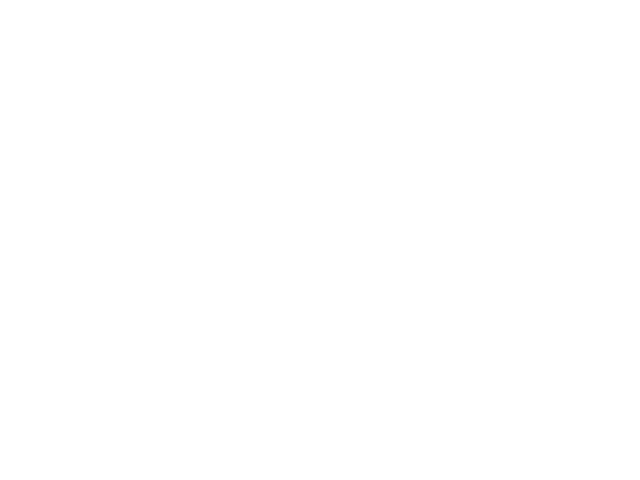

In [ ]:
# for creating a responsive plot
%matplotlib widget

# creating figure
fig = plt.figure()
ax = Axes3D(fig)

# creating the plot
plot = ax.scatter(i_set, j_set, results1)

# setting title and labels
ax.set_title("Ordering to Non Reciprocal Fuzzy")
ax.set_xlabel('i set')
ax.set_ylabel('j set')
ax.set_zlabel('results')

plt.show()

In [ ]:
CreateQuantitativeValues(10, 43, 57)

[43.0, 44.4, 45.8, 47.2, 48.6, 50.0, 51.4, 52.8, 54.2, 55.6, 57.0]

Support for third party widgets will remain active for the duration of the session. To disable support:

In [ ]:
from google.colab import output
output.disable_custom_widget_manager()

In [ ]:
additive = CreateFuzzyAdditiveReciprocalRelationFromSize(10)
for row in additive:
  for value in row:
    print("%.4f" % value, end = '\t')
  print()

0.5000	0.0000	0.0111	0.0222	0.0333	0.0444	0.0556	0.0667	0.0778	0.0889	
1.0000	0.5000	0.1000	0.1111	0.1222	0.1333	0.1444	0.1556	0.1667	0.1778	
0.9889	0.9000	0.5000	0.1889	0.2000	0.2111	0.2222	0.2333	0.2444	0.2556	
0.9778	0.8889	0.8111	0.5000	0.2667	0.2778	0.2889	0.3000	0.3111	0.3222	
0.9667	0.8778	0.8000	0.7333	0.5000	0.3333	0.3444	0.3556	0.3667	0.3778	
0.9556	0.8667	0.7889	0.7222	0.6667	0.5000	0.3889	0.4000	0.4111	0.4222	
0.9444	0.8556	0.7778	0.7111	0.6556	0.6111	0.5000	0.4333	0.4444	0.4556	
0.9333	0.8444	0.7667	0.7000	0.6444	0.6000	0.5667	0.5000	0.4667	0.4778	
0.9222	0.8333	0.7556	0.6889	0.6333	0.5889	0.5556	0.5333	0.5000	0.4889	
0.9111	0.8222	0.7444	0.6778	0.6222	0.5778	0.5444	0.5222	0.5111	0.5000	


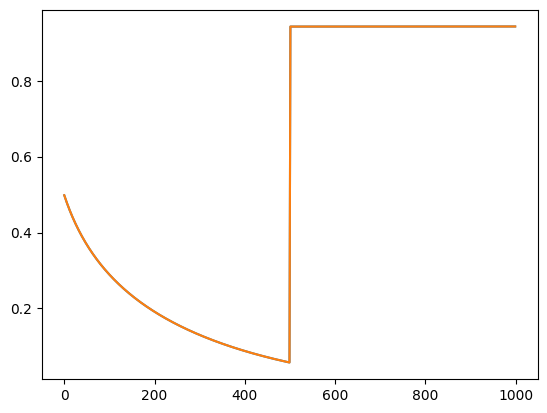

In [ ]:
size = 1000
index = 500

results1 = TestMultiplicativeByIndex(size, index, TransformMultiplicativeToFuzzyAdditiveReciprocal)
results2 = TestMultiplicativeByIndex(size, index, TransformMultiplicativeToFuzzyAdditiveReciprocal2)

plt.plot(results1)
plt.plot(results2)

In [ ]:
quantitative_values = np.array([35, 17, 90, 72])
minimum = 0
maximum = 100
print(QuantitativeToFuzzyNonReciprocal3(quantitative_values, minimum, maximum, False), '\n')
print(QuantitativeToFuzzyNonReciprocal42(quantitative_values, minimum, maximum, False), '\n')

[[1.         0.83361577 1.         1.        ]
 [1.         1.         1.         1.        ]
 [0.53881591 0.39505615 1.         0.83361577]
 [0.67812537 0.53881591 1.         1.        ]] 



NameError: ignored

In [ ]:
additive_relation = np.array([[0.5, 0.75, 0.866243380179482, 1],
                              [0.25, 0.5, 0.75, 0.866243380179482],
                              [0.133756619820518, 0.25, 0.5, 0.75],
                              [0, 0.133756619820518, 0.25, 0.5]])
print(FuzzyAdditiveReciprocalToMultiplicative(additive_relation), '\n')
print(FuzzyAdditiveReciprocalToMultiplicative42(additive_relation), '\n')

In [ ]:
non_reciprocal_relation = np.array([[1, 1, 1, 1],
                                    [0.5, 1, 1, 1],
                                    [0.267513239641037, 0.5, 1, 1],
                                    [0, 0.267513239641037, 0.5, 1]])
print(FuzzyNonReciprocalToFuzzyAdditiveReciprocal3(non_reciprocal_relation), '\n')
print(FuzzyNonReciprocalToFuzzyAdditiveReciprocal42(non_reciprocal_relation), '\n')

In [ ]:
multiplicative_relation = np.array([[1, 3, 5, 9],
                                    [1.0/3.0, 1, 3, 5],
                                    [0.2, 1.0/3.0, 1, 3],
                                    [1.0/9.0, 0.2, 1.0/3.0, 1]])
print(MultiplicativeToFuzzyAdditiveReciprocal(multiplicative_relation), '\n')
print(MultiplicativeToFuzzyAdditiveReciprocal42(multiplicative_relation), '\n')

In [ ]:
utility_vector = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
print(UtilityToFuzzyAdditiveReciprocal3(utility_vector), '\n')

In [ ]:
ordering = np.array([3, 1, 4, 2])

print(OrderingToMultiplicative(ordering), '\n')

In [ ]:
def oi(**kwargs):
  print(kwargs)
  print(kwargs['oi'])

oi(oi='hello', mundo='world')

In [ ]:
results[-2]

In [ ]:
[x/42 for x in range(43)]

In [ ]:
for i in range(10):
  print(np.random.randint(0, 100))

In [ ]:
7+6 + 5 + 4 + 3 + 2 + 1

In [ ]:
size = 8
(size)*(size-1) / 2

In [ ]:
CreateMultiplicativeRelationFromSize(100)

In [ ]:
x = 1/8
print(math.log(x, 9))
print(math.log(1/x, 9))
print(x / (1/x))
print(math.log(x / (1/x), 9))
print(math.log(x / (1/x), 9) * 0.5)
print(1 + math.log(x / (1/x), 9) * 0.5)

-0.946394630357186
0.946394630357186
0.015625
-1.892789260714372
-0.946394630357186
0.05360536964281404


In [ ]:
math.log(1/x, 9)

-0.946394630357186

In [ ]:
(1/x) / x

0.015625

In [ ]:
-0.946394630357186 * 2

-1.892789260714372

In [ ]:
def GetMultiplicativeValues(size):
  values = []
  for i in range(size):
    values.append(1/(1 + (8/size)*(i+1)))
  values.reverse()
  for i in range(size):
    values.append(1 + (8/size)*(i+1))
  return values

def TestMultiplicative(size, transformation_function):
  values = GetMultiplicativeValues(size)
  results = []
  for value in values:
    results.append(transformation_function(value))
  return values, results

def MultiplicativeToNonReciprocal(x):
  base = 9
  if math.log(x, base) < 0:
    return 1 + (0.5 * math.log(x / (1/x), base))
  else:
    return 1.0

def TestMultiplicativeToNonReciprocal(size):
  return TestMultiplicative(size, MultiplicativeToNonReciprocal)

def MultiplicativeToAdditive1(x):
  base = 9
  return 0.5 + (0.5 * math.log(x, base))

def MultiplicativeToAdditive2(x):
  base = 9
  return 0.5 * (1 + math.log(x, base))

def TestMultiplicativeToAdditive1(size):
  return TestMultiplicative(size, MultiplicativeToAdditive1)

def TestMultiplicativeToAdditive2(size):
  return TestMultiplicative(size, MultiplicativeToAdditive2)

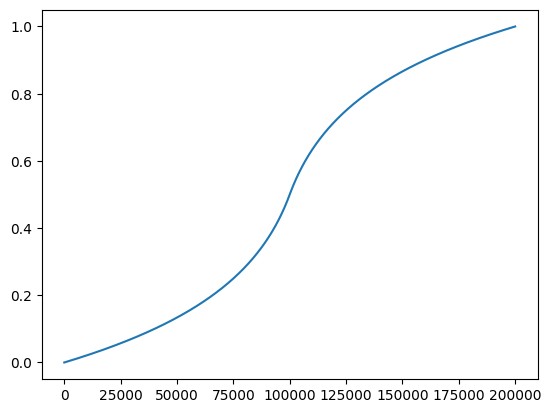

In [ ]:
values, results = TestMultiplicativeToAdditive2(100000)
#plt.plot(values)
plt.plot(results)

In [ ]:
a = [1/(x+1) for x in range(9)]
print(a)
values = []
for value in a:
  values.append(MultiplicativeToNonReciprocal(value))
print(values)

[1.0, 0.5, 0.3333333333333333, 0.25, 0.2, 0.16666666666666666, 0.14285714285714285, 0.125, 0.1111111111111111]
[1.0, 0.6845351232142713, 0.5, 0.3690702464285426, 0.26751323964103657, 0.18453512321427135, 0.11437812541928882, 0.05360536964281404, 0.0]


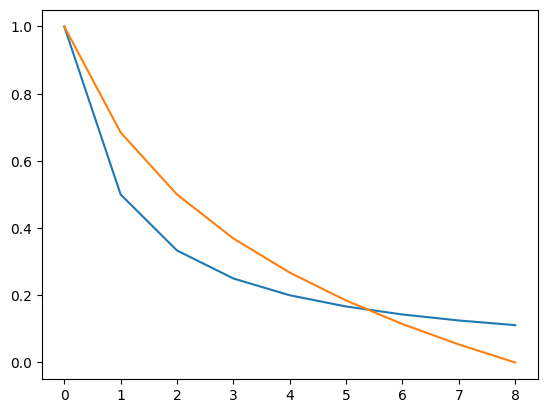

In [ ]:
plt.plot(a)
plt.plot(values)

In [ ]:
n = 1000
GetMultiplicativeValues(n)

[0.1111111111111111,
 0.11120996441281138,
 0.11130899376669635,
 0.11140819964349377,
 0.11150758251561106,
 0.11160714285714285,
 0.11170688114387846,
 0.11180679785330949,
 0.11190689346463742,
 0.11200716845878135,
 0.11210762331838565,
 0.11220825852782766,
 0.11230907457322552,
 0.11241007194244604,
 0.11251125112511251,
 0.11261261261261263,
 0.1127141568981064,
 0.11281588447653429,
 0.11291779584462512,
 0.11301989150090418,
 0.11312217194570136,
 0.11322463768115941,
 0.11332728921124206,
 0.1134301270417423,
 0.11353315168029064,
 0.11363636363636363,
 0.11373976342129209,
 0.11384335154826959,
 0.11394712853236098,
 0.11405109489051093,
 0.11415525114155252,
 0.11425959780621574,
 0.11436413540713633,
 0.11446886446886446,
 0.11457378551787352,
 0.11467889908256883,
 0.1147842056932966,
 0.11488970588235294,
 0.11499540018399264,
 0.11510128913443832,
 0.1152073732718894,
 0.11531365313653136,
 0.11542012927054476,
 0.1155268022181146,
 0.11563367252543941,
 0.1157407407407

# Additive Reciprocal Transitivity Testing

In [ ]:
def almost_equal(a, b, tolerance=1e-10):
  return abs(a - b) < tolerance

def TestARFPRTransitivity(rr, debug=False):
  n = len(rr)
  total = 0
  passing = 0
  for k in range(n):
    for j in range(n):
      if debug:
        print(f'k={k+1}, j={j+1}')
      for l in range(n):
        left = rr[k][j] - 0.5
        right = (rr[k][l] - 0.5) + (rr[l][j] - 0.5)
        if debug:
          print(f'l={l+1}\t{rr[k][j]} - 0.5 = ({rr[k][l]} - 0.5) + ({rr[l][j]} - 0.5)')
          print(f'   \t{left:.1f} = {right:.1f} ? {almost_equal(left, right)}')
        total += 1
        passing += 1 if almost_equal(left, right) else 0
  print(f'{passing}/{total} passed')

def TestARFPRConsistency(arfpr):
  n = len(arfpr)
  total = 0
  passing = 0
  for i in range(n):
    for j in range(i+1, n):
      for k in range(j+1, n):
        if i <= j <= k:
          sum = arfpr[i][j] + arfpr[j][k] + arfpr[k][i]
          print(sum)
          if almost_equal(sum, 1.5):
            passing += 1
          total += 1
  return passing, total

def TestMinTransitivity(nr, debug=False):
  n = len(nr)
  total = 0
  passing = 0
  for k in range(n):
    for l in range(n):
      if debug:
        print(f'k={k+1}, l={l+1}')
      for j in range(n):
        left = nr[k][l]
        right = min(nr[k][j], nr[j][l])
        if debug:
          print(f'j={j+1}\t{nr[k][l]} >= min({nr[k][j]}, {nr[j][l]})')
          print(f'   \t{left:.2f} >= {right:.2f} ? {left >= right}')
        total += 1
        passing += 1 if left >= right else 0
  print(f'{passing}/{total} passed')

def TestProductTransitivity(nr, debug=False):
  n = len(nr)
  total = 0
  passing = 0
  for k in range(n):
    for l in range(n):
      if debug:
        print(f'k={k+1}, l={l+1}')
      for j in range(n):
        left = nr[k][l]
        right = nr[k][j] * nr[j][l]
        if debug:
          print(f'j={j+1}\t{nr[k][l]} >= {nr[k][j]} * {nr[j][l]}')
          print(f'   \t{left:.2f} >= {right:.2f} ? {left >= right}')
        total += 1
        passing += 1 if left >= right else 0
  print(f'{passing}/{total} passed')

def TestLukasiewiczTransitivity(nr, debug=False):
  n = len(nr)
  total = 0
  passing = 0
  for k in range(n):
    for l in range(n):
      if debug:
        print(f'k={k+1}, l={l+1}')
      for j in range(n):
        left = nr[k][l]
        right = max(nr[k][j] + nr[j][l] - 1, 0)
        if debug:
          print(f'j={j+1}\t{nr[k][l]} >= max({nr[k][j]} + {nr[j][l]} - 1, 0)')
          print(f'   \t{left:.2f} >= {right:.2f} ? {left >= right}')
        total += 1
        passing += 1 if left >= right else 0
  print(f'{passing}/{total} passed')

def TestWeakTransitivity(nr, debug=False):
  n = len(nr)
  total = 0
  passing = 0
  for k in range(n):
    for l in range(n):
      if debug:
        print(f'k={k+1}, l={l+1}')
      for j in range(n):
        term1 = nr[k][j] >= nr[j][k]
        term2 = nr[j][l] >= nr[l][j] - 0.5
        term3 = nr[k][l] >= nr[l][k]
        if debug:
          print(f'j={j+1}')
          print(f'{nr[k][j]} >= {nr[j][k]} ? {term1}')
          print(f'{nr[j][l]} >= {nr[l][j]} + 0.5 ? {term2}')
          print(f'{nr[k][l]} >= {nr[l][k]} ? {term3}')
        total += 1
        if term1 and term2:
          passing += 1 if term3 else 0
        else:
          passing += 1
  print(f'{passing}/{total} passed')


In [ ]:
rr1 = np.array([[0.5, 1.0, 0.8, 0.5],
                [0.0, 0.5, 0.4, 0.0],
                [0.2, 0.6, 0.5, 0.2],
                [0.5, 1.0, 0.8, 0.5]])
rr2 = np.array([[0.5, 1.0, 0.0, 0.5],
                [0.0, 0.5, 1.0, 0.0],
                [1.0, 0.0, 0.5, 0.2],
                [0.5, 1.0, 0.8, 0.5]])
TestARFPRTransitivity(rr1)

nr1 = np.array([[1.0, 1.0, 1.0, 1.0],
                [0.75, 1.0, 1.0, 1.0],
                [0.5, 0.75, 1.0, 1.0],
                [0.25, 0.5, 0.75, 1.0]])
TestMinTransitivity(nr1)
TestLukasiewiczTransitivity(nr1, debug=True)

52/64 passed
60/64 passed
k=1, l=1
j=1	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=2	1.0 >= max(1.0 + 0.75 - 1, 0)
   	1.00 >= 0.75 ? True
j=3	1.0 >= max(1.0 + 0.5 - 1, 0)
   	1.00 >= 0.50 ? True
j=4	1.0 >= max(1.0 + 0.25 - 1, 0)
   	1.00 >= 0.25 ? True
k=1, l=2
j=1	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=2	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=3	1.0 >= max(1.0 + 0.75 - 1, 0)
   	1.00 >= 0.75 ? True
j=4	1.0 >= max(1.0 + 0.5 - 1, 0)
   	1.00 >= 0.50 ? True
k=1, l=3
j=1	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=2	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=3	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=4	1.0 >= max(1.0 + 0.75 - 1, 0)
   	1.00 >= 0.75 ? True
k=1, l=4
j=1	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=2	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=3	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
j=4	1.0 >= max(1.0 + 1.0 - 1, 0)
   	1.00 >= 1.00 ? True
k=2, l=1
j=1	0.75 >= m

In [ ]:
rr1 = np.array([[0.5, 1.0, 0.8, 0.5],
                [0.0, 0.5, 0.3, 0.0],
                [0.2, 0.7, 0.5, 0.2],
                [0.5, 1.0, 0.8, 0.5]])
nr1 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal(rr1)
print('rr1')
TestARFPRTransitivity(rr1)
TestWeakTransitivity(rr1)
print('nr1')
TestLukasiewiczTransitivity(rr1)
TestMinTransitivity(nr1)
TestProductTransitivity(nr1)
TestLukasiewiczTransitivity(nr1)
TestWeakTransitivity(nr1)
print('nr2')
nr2 = OrderingToFuzzyNonReciprocal2([0, 1, 2, 3])
# print(nr2)
TestMinTransitivity(nr2)
TestProductTransitivity(nr2)
TestLukasiewiczTransitivity(nr2)
TestWeakTransitivity(nr2)

rr1
64/64 passed
63/64 passed
nr1
64/64 passed
62/64 passed
62/64 passed
64/64 passed
63/64 passed
nr2
60/64 passed
60/64 passed
58/64 passed
61/64 passed


In [ ]:
# prompt: how do I make 0.5 - 0.5 == (0.8 - 0.5) + (0.2 - 0.5) be true?

import numpy as np

def almost_equal(a, b, tolerance=1e-10):
  return abs(a - b) < tolerance

# Example usage demonstrating the issue
print(0.5 - 0.5 == (0.8 - 0.5) + (0.2 - 0.5))  # Output: False

# Using almost_equal for floating-point comparisons
print(almost_equal(0.5 - 0.5, (0.8 - 0.5) + (0.2 - 0.5))) # Output: True


False
True


In [ ]:
# prompt: how do I print with a fixed lenght of decimal cases using print(f'{number}')?

# To print a number with a fixed number of decimal places using an f-string, use the following format:

number = 3.14159265359
print(f'{number:.2f}') # Output: 3.14
print(f'{number:.4f}') # Output: 3.1416


# Thesis examples

In [ ]:
rn = np.array([89, 105, 93, 85])
arfpr = QuantitativeToFuzzyAdditiveReciprocal(rn, min(rn), max(rn), True)
print(arfpr)
print()
nrfpr1 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal(arfpr)
nrfpr2 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal2(arfpr)
nrfpr3 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal3(arfpr)
print(nrfpr1)
print()
print(nrfpr2)
print()
print(nrfpr3)

[[0.5 0.1 0.4 0.6]
 [0.9 0.5 0.8 1. ]
 [0.6 0.2 0.5 0.7]
 [0.4 0.  0.3 0.5]]

[[1.  0.2 0.8 1. ]
 [1.  1.  1.  1. ]
 [1.  0.4 1.  1. ]
 [0.8 0.  0.6 1. ]]

[[1.         0.11111111 0.66666667 1.        ]
 [1.         1.         1.         1.        ]
 [1.         0.25       1.         1.        ]
 [0.66666667 0.         0.42857143 1.        ]]

[[1.         0.33333333 0.81649658 1.        ]
 [1.         1.         1.         1.        ]
 [1.         0.5        1.         1.        ]
 [0.81649658 0.         0.65465367 1.        ]]


In [ ]:
rn = np.array([4.2, 3.5, 4.2, 4.9])
arfpr = QuantitativeToFuzzyAdditiveReciprocal(rn, 0, 5, True)
print(arfpr)
print()
nrfpr1 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal(arfpr)
nrfpr2 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal2(arfpr)
nrfpr3 = FuzzyAdditiveReciprocalToFuzzyNonReciprocal3(arfpr)
print(nrfpr1)
print()
print(nrfpr2)
print()
print(nrfpr3)

[[0.5  0.57 0.5  0.43]
 [0.43 0.5  0.43 0.36]
 [0.5  0.57 0.5  0.43]
 [0.57 0.64 0.57 0.5 ]]

[[1.   1.   1.   0.86]
 [0.86 1.   0.86 0.72]
 [1.   1.   1.   0.86]
 [1.   1.   1.   1.  ]]

[[1.         1.         1.         0.75438596]
 [0.75438596 1.         0.75438596 0.5625    ]
 [1.         1.         1.         0.75438596]
 [1.         1.         1.         1.        ]]

[[1.         1.         1.         0.86855395]
 [0.86855395 1.         0.86855395 0.75      ]
 [1.         1.         1.         0.86855395]
 [1.         1.         1.         1.        ]]


In [ ]:
oa = np.array([2, 4, 1, 3])
nrfpr = OrderingToFuzzyNonReciprocal(oa)
nrfpr

array([[1.        , 1.        , 0.33333333, 1.        ],
       [0.16666667, 1.        , 0.        , 0.33333333],
       [1.        , 1.        , 1.        , 1.        ],
       [0.33333333, 1.        , 0.16666667, 1.        ]])

In [ ]:
nrfpr_from_lts = np.array([[1, 0, 0, 1],
                           [1, 1, 0.5, 1],
                           [1, 1, 1, 1],
                           [0.5, 0, 0, 1]])
nrfpr_from_lts

array([[1. , 0. , 0. , 1. ],
       [1. , 1. , 0.5, 1. ],
       [1. , 1. , 1. , 1. ],
       [0.5, 0. , 0. , 1. ]])

In [ ]:
mpr = np.array([[  1, 9,   5,   1],
                [1/9, 1, 1/5, 1/9],
                [1/5, 5,   1, 1/5],
                [  1, 9,   5,   1]])
nrfpr = MultiplicativeToFuzzyNonReciprocal(mpr)
nrfpr

array([[1.        , 1.        , 1.        , 1.        ],
       [0.        , 1.        , 0.26751324, 0.        ],
       [0.26751324, 1.        , 1.        , 0.26751324],
       [1.        , 1.        , 1.        , 1.        ]])

In [ ]:
uv = np.array([0.2, 0.4, 1, 0.7])
print(uv)
print()
nrfpr1 = UtilityToFuzzyNonReciprocal(uv)
nrfpr2 = UtilityToFuzzyNonReciprocal2(uv)
nrfpr3 = UtilityToFuzzyNonReciprocal3(uv)
nrfpr4 = UtilityToFuzzyNonReciprocal4(uv)
print(nrfpr1)
print()
print(nrfpr2)
print()
print(nrfpr3)
print()
print(nrfpr4)
print()

[0.2 0.4 1.  0.7]

[[1.  0.8 0.2 0.5]
 [1.  1.  0.4 0.7]
 [1.  1.  1.  1. ]
 [1.  1.  0.7 1. ]]

[[1.         0.5        0.2        0.28571429]
 [1.         1.         0.4        0.57142857]
 [1.         1.         1.         1.        ]
 [1.         1.         0.7        1.        ]]

[[1.         0.70710678 0.4472136  0.53452248]
 [1.         1.         0.63245553 0.75592895]
 [1.         1.         1.         1.        ]
 [1.         1.         0.83666003 1.        ]]

[[1.         0.25       0.04       0.08163265]
 [1.         1.         0.16       0.32653061]
 [1.         1.         1.         1.        ]
 [1.         1.         0.49       1.        ]]



# Thesis Chapter 5

In [ ]:
size = 100
i_set, j_set, results = TestOACombinations(size, keep_only_below_1=False)
results.sort()
results = set(results)
results

{0.0,
 0.0050505050505050275,
 0.01010101010101011,
 0.015151515151515138,
 0.02020202020202022,
 0.02525252525252525,
 0.030303030303030276,
 0.03535353535353536,
 0.04040404040404039,
 0.04545454545454547,
 0.0505050505050505,
 0.05555555555555558,
 0.06060606060606061,
 0.06565656565656564,
 0.07070707070707072,
 0.07575757575757575,
 0.08080808080808083,
 0.08585858585858586,
 0.09090909090909088,
 0.09595959595959597,
 0.101010101010101,
 0.10606060606060608,
 0.1111111111111111,
 0.11616161616161619,
 0.12121212121212122,
 0.12626262626262624,
 0.13131313131313133,
 0.13636363636363635,
 0.14141414141414144,
 0.14646464646464646,
 0.1515151515151515,
 0.15656565656565657,
 0.1616161616161616,
 0.16666666666666669,
 0.1717171717171717,
 0.17676767676767674,
 0.18181818181818182,
 0.18686868686868685,
 0.19191919191919193,
 0.19696969696969696,
 0.20202020202020204,
 0.20707070707070707,
 0.2121212121212121,
 0.21717171717171718,
 0.2222222222222222,
 0.2272727272727273,
 0.2323232

In [ ]:
# Calculate cumulative metrics for plotting
plot_points = np.arange(200, long_run_simulations, 200)
cumulative_means = []
ci_upper_bounds = []
ci_lower_bounds = []

Z = 1.96  # For 95% CI

for i in plot_points:
    current_data = exploratory_results[:i]
    mean = np.mean(current_data)
    std_dev = np.std(current_data)
    margin_of_error = Z * (std_dev / np.sqrt(i))

    cumulative_means.append(mean)
    ci_upper_bounds.append(mean + margin_of_error)
    ci_lower_bounds.append(mean - margin_of_error)

# Plot the convergence with CI bands
plt.figure(figsize=(10, 6))
plt.plot(plot_points, cumulative_means, label='Cumulative Mean')
plt.fill_between(plot_points, ci_lower_bounds, ci_upper_bounds, color='skyblue', alpha=0.4, label='95% Confidence Interval')
plt.title('Convergence of Mean Profit with 95% Confidence Interval')
plt.xlabel('Number of Simulations')
plt.ylabel('Mean Profit ($)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import plotly.graph_objects as go

fig = go.Figure(data=[go.Scatter3d(
    x=df['UV(i)'],
    y=df['UV(j)'],
    z=df['Result'],
    mode='lines',
    marker=dict(
        size=2,
        color=df['Result'],  # Your continuous variable for coloring
        colorscale='Inferno', # Choose a colorscale
        colorbar=dict(title='Result')
    ),
    line=dict(
        color='darkblue', # You might want to set a base line color
        width=2
    )
)])

fig.update_layout(
    title='Transformation of Utility Values to NRFPR',
    scene = dict(
        xaxis_title='UV(i)',
        yaxis_title='UV(j)',
        zaxis_title='Result'
    ),
    width=800,
    margin=dict(r=20, b=10, l=10, t=40)
)

fig.show()

In [ ]:
import plotly.graph_objects as go
import numpy as np

fig = go.Figure()

# Define colorscale
colorscale = 'Inferno' # Or any other colorscale you prefer
color_values = df['Result']

# Normalize color values to the range [0, 1]
norm_color_values = (color_values - color_values.min()) / (color_values.max() - color_values.min())

# Get the colors from the colorscale
from plotly.colors import sample_colorscale
colors = sample_colorscale(colorscale, norm_color_values)

# Plot each segment individually
for i in range(len(df) - 1):
    fig.add_trace(go.Scatter3d(
        x=df['UV(i)'][i:i+2],
        y=df['UV(j)'][i:i+2],
        z=df['Result'][i:i+2],
        mode='lines',
        line=dict(
            color=colors[i], # Color the segment based on the value at the start of the segment
            width=4
        ),
        showlegend=False # Hide legend for individual segments
    ))

fig.update_layout(
    title='Transformation of Utility Values to NRFPR with Heatmap-like Line',
    scene = dict(
        xaxis_title='UV(i)',
        yaxis_title='UV(j)',
        zaxis_title='Result'
    ),
    width=800,
    margin=dict(r=20, b=10, l=10, t=40)
)

# Add a color bar manually for reference
# This is a simplified approach, a proper color bar might require more customization
# You could potentially use go.Scatter or go.Heatmap in a separate subplot for a dedicated colorbar

# Create a dummy scatter plot with the colorscale to display the colorbar
fig.add_trace(go.Scatter3d(
    x=[None], # No actual data points
    y=[None],
    z=[None],
    mode='markers',
    marker=dict(
        colorscale=colorscale,
        showscale=True,
        colorbar=dict(title='Result'),
        cmin=color_values.min(),
        cmax=color_values.max()
    ),
    hoverinfo='none'
))


fig.show()

KeyboardInterrupt: 

In [ ]:
ahp = [1/9, 1/8, 1/7, 1/6, 1/5, 1/4, 1/3, 1/2, 1, 2, 3, 4, 5, 6, 7, 8, 9]

for mpr_value in ahp:
  nrfpr_value = TransformMultiplicativeToFuzzyNonReciprocalX2(mpr_value)
  print(f'{mpr_value:.3f} -> {nrfpr_value:.3f}')

0.111 -> 10.000
0.125 -> 8.875
0.143 -> 7.750
0.167 -> 6.625
0.200 -> 5.500
0.250 -> 4.375
0.333 -> 3.250
0.500 -> 2.125
1.000 -> 1.000
2.000 -> 1.000
3.000 -> 1.000
4.000 -> 1.000
5.000 -> 1.000
6.000 -> 1.000
7.000 -> 1.000
8.000 -> 1.000
9.000 -> 1.000


In [ ]:
mpr = RandomMPRAllValues(4)

In [ ]:
nrfpr1 = TransformMPR(mpr, FROM_MPR.TO_NRFPR_ORIGINAL)
nrfpr2 = TransformMPR(mpr, FROM_MPR.TO_NRFPR_PROPOSED)
mpr, nrfpr1, nrfpr2

(array([[1.        , 4.        , 0.14285714, 6.        ],
        [0.25      , 1.        , 0.11111111, 1.5       ],
        [7.        , 9.        , 1.        , 9.        ],
        [0.16666667, 0.66666667, 0.11111111, 1.        ]]),
 array([[1.        , 1.        , 0.11437813, 1.        ],
        [0.36907025, 1.        , 0.        , 1.        ],
        [1.        , 1.        , 1.        , 1.        ],
        [0.18453512, 0.81546488, 0.        , 1.        ]]),
 array([[1.        , 1.        , 0.03571429, 1.        ],
        [0.15625   , 1.        , 0.        , 1.        ],
        [1.        , 1.        , 1.        , 1.        ],
        [0.0625    , 0.625     , 0.        , 1.        ]]))

# Distributional Sensitivity Analysis (Section 5.4, Table 5) & Empirical Case Studies (Section 6, Tables 6–9)
<!-- SECTION_5_4_AND_6_EXTENSION -->
The cells below execute:
1. **Distributional Sensitivity Analysis (Section 5.4, Table 5):** Evaluates the three combined-format portfolios (`lowest_performing`, `highest_performing`, and `formats_combined_proposed`) under three distinct stochastic input distributions (`'uniform'`, `'normal'`, and `'beta'`) and reports both the **Maximal Contribution Gap ($	ext{MCG} = \max_c U_c - \min_c L_c$)** and **Central Contribution Gap ($	ext{CCG} = \max_c \hat{c}_c - \min_c \hat{c}_c$)**.
2. **Real-World Empirical Case Studies (Section 6 & Appendices A–B):** Evaluates **Case Study 1 (Cost of Doing Business Index, $n=17, m=11$)** and **Case Study 2 (Multi-Expert Social Exclusion Index, $n=14, m=4$)** under both the Legacy Nonlinear and Proposed Linear transformation portfolios, outputting Tables 6–9 and generating the 4-panel gridded comparison chart (`case_studies_comparison.png`).

In [ ]:
#@title Distributional Sensitivity Analysis (Section 5.4, Table 5)
# <!-- SECTION_5_4_AND_6_EXTENSION -->

def EvaluatePortfolioDistribution(portfolio_cfg, distribution='uniform', k_per_run=10000, num_runs=5, seed=42):
  np.random.seed(seed)
  criteria = portfolio_cfg['criteria_names']
  dfs = []
  for r in range(num_runs):
    df_run = MonteCarloSimulation(
        num_scenarios=k_per_run,
        technique=OrlovskyTechniques.EARLY_AGGREGATION,
        criteria_names=criteria,
        format_types=portfolio_cfg['format_types'],
        transformation_methods=portfolio_cfg['transformation_methods'],
        show_additional_stats=True,
        debug_level=0,
        distribution=distribution
    )
    dfs.append(df_run)
  full_df = pd.concat(dfs, ignore_index=True)

  def compute_gaps(metric_prefix):
    ests, lbs, ubs = [], [], []
    for c in criteria:
      series = full_df[f'{metric_prefix}_{c}']
      m = np.mean(series)
      se = np.std(series) / np.sqrt(len(series))
      ci = 1.96 * se
      ests.append(m)
      lbs.append(m - ci)
      ubs.append(m + ci)
    return max(ubs) - min(lbs), max(ests) - min(ests)

  mcg_rmc, ccg_rmc = compute_gaps('relative_avg')
  mcg_rhpc, ccg_rhpc = compute_gaps('relative_high_owa')
  return {
      'MCG_RMC': mcg_rmc, 'CCG_RMC': ccg_rmc,
      'MCG_RHPC': mcg_rhpc, 'CCG_RHPC': ccg_rhpc
  }

combined_portfolios = [
    {'name': 'lowest_performing',
     'criteria_names': ['rn_from_data', 'rn_fixed_scale', 'uv_cardinal', 'uv_ordinal', 'oa', 'mpr', 'arfpr'],
     'format_types': [PreferenceFormatType.RN_FROM_DATA, PreferenceFormatType.RN_FIXED_SCALE,
                      PreferenceFormatType.UV_CARDINAL, PreferenceFormatType.UV_ORDINAL,
                      PreferenceFormatType.OA, PreferenceFormatType.MPR_ALL_VALUES, PreferenceFormatType.ARFPR],
     'transformation_methods': [FROM_RN.TO_NRFPR_DIV, FROM_RN.TO_NRFPR_DIV,
                                FROM_UV.TO_NRFPR_DIV_SQRT, FROM_UV.TO_NRFPR_DIV_SQRD,
                                FROM_OA.TO_NRFPR_ORIGINAL, FROM_MPR.TO_NRFPR_ORIGINAL, FROM_ARFPR.TO_NRFPR_DIV]},
    {'name': 'highest_performing',
     'criteria_names': ['rn_from_data', 'rn_fixed_scale', 'uv_cardinal', 'uv_ordinal', 'oa', 'mpr', 'arfpr'],
     'format_types': [PreferenceFormatType.RN_FROM_DATA, PreferenceFormatType.RN_FIXED_SCALE,
                      PreferenceFormatType.UV_CARDINAL, PreferenceFormatType.UV_ORDINAL,
                      PreferenceFormatType.OA, PreferenceFormatType.MPR_ALL_VALUES, PreferenceFormatType.ARFPR],
     'transformation_methods': [FROM_RN.TO_NRFPR_DIV_SQRT, FROM_RN.TO_NRFPR_DIV_SQRT,
                                FROM_UV.TO_NRFPR_DISTANCE, FROM_UV.TO_NRFPR_DISTANCE,
                                FROM_OA.TO_NRFPR_ORIGINAL, FROM_MPR.TO_NRFPR_ORIGINAL, FROM_ARFPR.TO_NRFPR_DIV_SQRT]},
    {'name': 'formats_combined_proposed',
     'criteria_names': ['rn_from_data', 'rn_fixed_scale', 'uv_cardinal', 'uv_ordinal', 'oa', 'mpr', 'arfpr'],
     'format_types': [PreferenceFormatType.RN_FROM_DATA, PreferenceFormatType.RN_FIXED_SCALE,
                      PreferenceFormatType.UV_CARDINAL, PreferenceFormatType.UV_ORDINAL,
                      PreferenceFormatType.OA, PreferenceFormatType.MPR_ALL_VALUES, PreferenceFormatType.ARFPR],
     'transformation_methods': [FROM_RN.TO_NRFPR_DIFF, FROM_RN.TO_NRFPR_DIFF,
                                FROM_UV.TO_NRFPR_DISTANCE, FROM_UV.TO_NRFPR_DISTANCE,
                                FROM_OA.TO_NRFPR_PROPOSED_1, FROM_MPR.TO_NRFPR_PROPOSED, FROM_ARFPR.TO_NRFPR_DIFF]}
]

# Set run_sensitivity = True to execute the full distributional sensitivity sweep
run_sensitivity = False
if run_sensitivity:
  for dist_name in ['uniform', 'normal', 'beta']:
    print(f"\n=== DISTRIBUTION: {dist_name.upper()} ===")
    for p_cfg in combined_portfolios:
      res = EvaluatePortfolioDistribution(p_cfg, distribution=dist_name, k_per_run=10000, num_runs=5)
      print(f"  {p_cfg['name']:26s} -> RMC MCG (CCG): {res['MCG_RMC']:.3f} ({res['CCG_RMC']:.3f}) | RHPC MCG (CCG): {res['MCG_RHPC']:.3f} ({res['CCG_RHPC']:.3f})")


In [ ]:
#@title Real-World Empirical Case Studies (Section 6 & Appendices A-B: CDBI & Social Exclusion)
# <!-- SECTION_5_4_AND_6_EXTENSION -->

def EvaluateEmpiricalCaseStudy(r_set, criteria_names, alt_codes, title):
  result = FirstTechnique(r_set, criteria_names)
  nd = result['nd_set']
  nd_crit = result['nd_contributing_criteria']

  avg_stats = CalculateAvgStats(result, criteria_names)
  owa_stats = CalculateHighOWAStats(result, criteria_names)

  print(f"\n{'='*72}\n{title}\n{'='*72}")
  print("Alternative Non-Dominance Degrees (x^ND_j) and Decisive Criteria Sets (S^ND_j):")
  for idx in np.argsort(nd)[::-1]:
    dec_str = ', '.join(sorted(list(nd_crit[idx]))) if nd_crit[idx] else 'None (Unbounded)'
    print(f"  {alt_codes[idx]:5s} : x^ND = {nd[idx]:.4f} | Bounded by: {{{dec_str}}}")

  print("\nCriterion Contributions (RMC_c and RHPC_c):")
  rmc_vals, rhpc_vals = {}, {}
  for c in criteria_names:
    rmc_vals[c] = avg_stats[f'avg_{c}'] / avg_stats['avg_nd_set']
    rhpc_vals[c] = owa_stats[f'high_owa_{c}'] / owa_stats['high_owa_nd_set']
    print(f"  {c:10s} : RMC = {rmc_vals[c]:.4f} | RHPC = {rhpc_vals[c]:.4f}")

  mcg_rmc = max(rmc_vals.values()) - min(rmc_vals.values())
  mcg_rhpc = max(rhpc_vals.values()) - min(rhpc_vals.values())
  print(f"\nMaximal / Central Contribution Gap (Single Deterministic Scenario -> MCG = CCG):")
  print(f"  RMC Gap  = {mcg_rmc:.4f}")
  print(f"  RHPC Gap = {mcg_rhpc:.4f}")
  return rmc_vals, rhpc_vals, nd, nd_crit

# ------------------------------------------------------------------------------
# CASE STUDY 1: Cost of Doing Business Index (CDBI) - 17 Countries, 11 Experts
# ------------------------------------------------------------------------------
codes_cdbi = ['ARG', 'BOL', 'BRA', 'CHL', 'COL', 'CRI', 'ECU', 'SLV', 'GTM',
              'HND', 'MEX', 'NIC', 'PAN', 'PRY', 'PER', 'URY', 'VEN']

oa_cdbi = np.array([
    [ 8,  6, 11, 13, 12,  5,  7, 13,  9, 13],
    [17, 16, 14, 15, 16, 17, 15, 16, 16, 12],
    [13, 14, 17, 17, 17, 14, 17, 17, 17, 16],
    [ 1,  1,  2,  1,  1,  1,  1,  3,  2,  3],
    [ 6,  5,  4,  7,  6,  9,  6,  7,  4,  7],
    [ 3,  4,  6,  4,  8,  7,  9,  2,  6,  1],
    [15, 15, 15, 11, 14, 15, 14, 10, 15, 14],
    [ 4,  9,  9,  6,  7,  4,  8,  9,  8,  8],
    [10,  7,  5,  8,  4, 10,  5,  5,  5, 10],
    [11, 12, 13,  9,  9, 11, 11, 11, 12, 11],
    [ 2,  2,  1,  5,  2,  3,  2,  6,  1,  4],
    [14, 13, 10, 12, 11, 13, 10, 15, 11, 15],
    [ 5,  8,  3,  2,  3,  6,  3,  1,  3,  2],
    [ 9, 10,  7, 14,  5, 12,  4, 12, 10,  6],
    [ 7,  3,  8, 10, 10,  8, 12,  8,  7,  9],
    [12, 11, 12,  3, 13,  2, 13,  4, 13,  5],
    [16, 17, 16, 16, 15, 16, 16, 14, 14, 17]
], dtype=float)

mpr_cdbi = np.array([
    [1, 5, 2, 1/6, 1/5, 1/5, 4, 1, 1/3, 3, 1/6, 2, 1/6, 1/3, 1/4, 1/3, 4],
    [1/5, 1, 1/3, 1/9, 1/8, 1/8, 1/2, 1/4, 1/6, 1/3, 1/9, 1/3, 1/9, 1/6, 1/7, 1/6, 1/2],
    [1/2, 3, 1, 1/7, 1/6, 1/6, 2, 1/2, 1/4, 2, 1/7, 1, 1/7, 1/4, 1/5, 1/4, 3],
    [6, 9, 7, 1, 2, 2, 8, 5, 4, 7, 1, 6, 1, 4, 3, 4, 8],
    [5, 8, 6, 1/2, 1, 1, 7, 4, 3, 6, 1/2, 5, 1/2, 3, 2, 3, 7],
    [5, 8, 6, 1/2, 1, 1, 7, 4, 3, 6, 1/2, 5, 1/2, 3, 2, 3, 7],
    [1/4, 2, 1/2, 1/8, 1/7, 1/7, 1, 1/3, 1/5, 1/2, 1/8, 1/2, 1/8, 1/5, 1/6, 1/5, 1],
    [1, 4, 2, 1/5, 1/4, 1/4, 3, 1, 1/2, 2, 1/5, 2, 1/5, 1/2, 1/3, 1/2, 4],
    [3, 6, 4, 1/4, 1/3, 1/3, 5, 2, 1, 4, 1/4, 3, 1/4, 1, 1/2, 1, 5],
    [1/3, 3, 1/2, 1/7, 1/6, 1/6, 2, 1/2, 1/4, 1, 1/7, 1, 1/7, 1/4, 1/5, 1/4, 2],
    [6, 9, 7, 1, 2, 2, 8, 5, 4, 7, 1, 6, 1, 4, 3, 4, 8],
    [1/2, 3, 1, 1/6, 1/5, 1/5, 2, 1/2, 1/3, 1, 1/6, 1, 1/6, 1/3, 1/4, 1/3, 2],
    [6, 9, 7, 1, 2, 2, 8, 5, 4, 7, 1, 6, 1, 4, 3, 4, 8],
    [3, 6, 4, 1/4, 1/3, 1/3, 5, 2, 1, 4, 1/4, 3, 1/4, 1, 1/2, 1, 5],
    [4, 7, 5, 1/3, 1/2, 1/2, 6, 3, 2, 5, 1/3, 4, 1/3, 2, 1, 2, 6],
    [3, 6, 4, 1/4, 1/3, 1/3, 5, 2, 1, 4, 1/4, 3, 1/4, 1, 1/2, 1, 5],
    [1/4, 2, 1/3, 1/8, 1/7, 1/7, 1, 1/4, 1/5, 1/2, 1/8, 1/2, 1/8, 1/5, 1/6, 1/5, 1]
], dtype=float)

c_cdbi = [f'E{k}_OA' for k in range(1, 11)] + ['E11_MPR']
r_cdbi_legacy = [TransformOA(oa_cdbi[:, k], FROM_OA.TO_NRFPR_ORIGINAL) for k in range(10)] + [TransformMPR(mpr_cdbi, FROM_MPR.TO_NRFPR_ORIGINAL)]
r_cdbi_prop   = [TransformOA(oa_cdbi[:, k], FROM_OA.TO_NRFPR_PROPOSED_1) for k in range(10)] + [TransformMPR(mpr_cdbi, FROM_MPR.TO_NRFPR_PROPOSED)]

cdbi_leg_rmc, cdbi_leg_rhpc, _, _ = EvaluateEmpiricalCaseStudy(r_cdbi_legacy, c_cdbi, codes_cdbi, "Case Study 1 (CDBI) - Legacy Portfolio")
cdbi_prp_rmc, cdbi_prp_rhpc, _, _ = EvaluateEmpiricalCaseStudy(r_cdbi_prop, c_cdbi, codes_cdbi, "Case Study 1 (CDBI) - Proposed Linear Portfolio")

# ------------------------------------------------------------------------------
# CASE STUDY 2: Multi-Expert Social Exclusion Index - 14 Indicators, 4 Experts
# ------------------------------------------------------------------------------
codes_se = ['VD1', 'VD2', 'VD3', 'VD4', 'VE1', 'VE2', 'VE3', 'VED1', 'VED2', 'VH2', 'VH3', 'VH4', 'VH5', 'VH1']
oa_e1_se = np.array([14, 11, 13, 12, 3, 1, 2, 9, 10, 5, 7, 8, 6, 4], dtype=float)
rn_e2_se = np.array([ 8,  8,  8,  7, 10, 1, 8, 10, 10, 1, 8, 8, 7, 10], dtype=float)
rn_e3_se = np.array([ 6,  7,  2,  4, 10, 2, 8,  9, 10, 1, 10, 10, 5, 10], dtype=float)
mpr_e4_se = np.array([
    [1, 1/5, 1, 1, 1/7, 1/7, 1, 1/3, 1/9, 1/5, 1/3, 1/3, 1, 1/7],
    [5, 1, 3, 5, 1/3, 1/3, 3, 3, 1/3, 1/3, 1, 1, 3, 1/5],
    [1, 1/3, 1, 1, 1/5, 1/5, 1, 1/3, 1/5, 1/5, 1/3, 1/3, 1, 1/5],
    [1, 1/5, 1, 1, 1/5, 1/5, 1, 1/3, 1/7, 1/5, 1/3, 1/3, 1, 1/5],
    [7, 3, 5, 5, 1, 1, 5, 5, 1, 1, 3, 3, 5, 1],
    [7, 3, 5, 5, 1, 1, 5, 5, 1, 1, 3, 3, 5, 1],
    [1, 1/3, 1, 1, 1/5, 1/5, 1, 1, 1/5, 1/5, 1/3, 1/3, 1, 1/5],
    [3, 1/3, 3, 3, 1/5, 1/5, 1, 1, 1/7, 1/5, 1/3, 1/3, 1, 1/3],
    [9, 3, 5, 7, 1, 1, 5, 7, 1, 1, 3, 3, 5, 1],
    [5, 3, 5, 5, 1, 1, 5, 5, 1, 1, 5, 5, 5, 1],
    [3, 1, 3, 3, 1/3, 1/3, 3, 3, 1/3, 1/5, 1, 1, 3, 1/3],
    [3, 1, 3, 3, 1/3, 1/3, 3, 3, 1/5, 1/5, 1, 1, 3, 1/3],
    [1, 1, 1, 1, 1/5, 1/5, 1, 1, 1/5, 1/5, 1/3, 1/3, 1, 1/7],
    [7, 5, 5, 5, 1, 1, 5, 3, 1, 1, 3, 3, 7, 1]
], dtype=float)

c_se = ['E1 (OA)', 'E2 (RN/UV)', 'E3 (RN/UV)', 'E4 (MPR)']
r_se_legacy = [
    TransformOA(oa_e1_se, FROM_OA.TO_NRFPR_ORIGINAL),
    TransformUV(rn_e2_se / 10.0, FROM_UV.TO_NRFPR_DIV),
    TransformUV(rn_e3_se / 10.0, FROM_UV.TO_NRFPR_DIV),
    TransformMPR(mpr_e4_se, FROM_MPR.TO_NRFPR_ORIGINAL)
]
r_se_prop = [
    TransformOA(oa_e1_se, FROM_OA.TO_NRFPR_PROPOSED_1),
    TransformRN(rn_e2_se, FROM_RN.TO_NRFPR_DIFF, is_maximization=True, minimum=1.0, maximum=10.0),
    TransformRN(rn_e3_se, FROM_RN.TO_NRFPR_DIFF, is_maximization=True, minimum=1.0, maximum=10.0),
    TransformMPR(mpr_e4_se, FROM_MPR.TO_NRFPR_PROPOSED)
]

se_leg_rmc, se_leg_rhpc, _, _ = EvaluateEmpiricalCaseStudy(r_se_legacy, c_se, codes_se, "Case Study 2 (Social Exclusion) - Legacy Portfolio")
se_prp_rmc, se_prp_rhpc, _, _ = EvaluateEmpiricalCaseStudy(r_se_prop, c_se, codes_se, "Case Study 2 (Social Exclusion) - Proposed Linear Portfolio")

# ------------------------------------------------------------------------------
# Plot 4-Panel Gridded Case Studies Comparison Figure (Figure 4 in Manuscript)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), dpi=300)
x1 = np.arange(len(c_cdbi))
w = 0.36

axes[0, 0].bar(x1 - w/2, [cdbi_leg_rmc[c] for c in c_cdbi], width=w, label='Legacy Transformations', color='#d95f02', alpha=0.85, edgecolor='black')
axes[0, 0].bar(x1 + w/2, [cdbi_prp_rmc[c] for c in c_cdbi], width=w, label='Proposed Linear Transformations', color='#1b9e77', alpha=0.85, edgecolor='black')
axes[0, 0].set_title('Case Study 1 (CDBI): Relative Mean Contribution (RMC)', fontsize=11, fontweight='bold')
axes[0, 0].set_xticks(x1)
axes[0, 0].set_xticklabels(c_cdbi, rotation=30, ha='right', fontsize=9.5)
axes[0, 0].set_ylim(0, 1.1)
axes[0, 0].set_ylabel('RMC', fontsize=10.5)
axes[0, 0].minorticks_on()
axes[0, 0].grid(True, which='both', linestyle='--', alpha=0.6)
axes[0, 0].legend(loc='lower right', fontsize=9)

axes[0, 1].bar(x1 - w/2, [cdbi_leg_rhpc[c] for c in c_cdbi], width=w, label='Legacy Transformations', color='#d95f02', alpha=0.85, edgecolor='black')
axes[0, 1].bar(x1 + w/2, [cdbi_prp_rhpc[c] for c in c_cdbi], width=w, label='Proposed Linear Transformations', color='#1b9e77', alpha=0.85, edgecolor='black')
axes[0, 1].set_title('Case Study 1 (CDBI): Relative High-Perf. Contribution (RHPC)', fontsize=11, fontweight='bold')
axes[0, 1].set_xticks(x1)
axes[0, 1].set_xticklabels(c_cdbi, rotation=30, ha='right', fontsize=9.5)
axes[0, 1].set_ylim(0, 1.1)
axes[0, 1].set_ylabel('RHPC', fontsize=10.5)
axes[0, 1].minorticks_on()
axes[0, 1].grid(True, which='both', linestyle='--', alpha=0.6)
axes[0, 1].legend(loc='lower right', fontsize=9)

x2 = np.arange(len(c_se))
axes[1, 0].bar(x2 - w/2, [se_leg_rmc[c] for c in c_se], width=w, label='Legacy Transformations', color='#d95f02', alpha=0.85, edgecolor='black')
axes[1, 0].bar(x2 + w/2, [se_prp_rmc[c] for c in c_se], width=w, label='Proposed Linear Transformations', color='#1b9e77', alpha=0.85, edgecolor='black')
axes[1, 0].set_title('Case Study 2 (Social Exclusion): Relative Mean Contribution (RMC)', fontsize=11, fontweight='bold')
axes[1, 0].set_xticks(x2)
axes[1, 0].set_xticklabels(c_se, fontsize=10)
axes[1, 0].set_ylim(0, 1.1)
axes[1, 0].set_ylabel('RMC', fontsize=10.5)
axes[1, 0].minorticks_on()
axes[1, 0].grid(True, which='both', linestyle='--', alpha=0.6)
axes[1, 0].legend(loc='lower right', fontsize=9)

axes[1, 1].bar(x2 - w/2, [se_leg_rhpc[c] for c in c_se], width=w, label='Legacy Transformations', color='#d95f02', alpha=0.85, edgecolor='black')
axes[1, 1].bar(x2 + w/2, [se_prp_rhpc[c] for c in c_se], width=w, label='Proposed Linear Transformations', color='#1b9e77', alpha=0.85, edgecolor='black')
axes[1, 1].set_title('Case Study 2 (Social Exclusion): Relative High-Perf. Contribution (RHPC)', fontsize=11, fontweight='bold')
axes[1, 1].set_xticks(x2)
axes[1, 1].set_xticklabels(c_se, fontsize=10)
axes[1, 1].set_ylim(0, 1.1)
axes[1, 1].set_ylabel('RHPC', fontsize=10.5)
axes[1, 1].minorticks_on()
axes[1, 1].grid(True, which='both', linestyle='--', alpha=0.6)
axes[1, 1].legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig('case_studies_comparison.png', dpi=300)
plt.show()



Case Study 1 (CDBI) - Legacy Portfolio
Alternative Non-Dominance Degrees (x^ND_j) and Decisive Criteria Sets (S^ND_j):
  CHL   : x^ND = 1.0000 | Bounded by: {E10_OA, E11_MPR, E1_OA, E2_OA, E3_OA, E4_OA, E5_OA, E6_OA, E7_OA, E8_OA, E9_OA}
  MEX   : x^ND = 0.9062 | Bounded by: {E3_OA, E9_OA}
  PAN   : x^ND = 0.8438 | Bounded by: {E8_OA}
  CRI   : x^ND = 0.8125 | Bounded by: {E10_OA}
  SLV   : x^ND = 0.2500 | Bounded by: {E10_OA, E11_MPR, E1_OA, E2_OA, E3_OA, E4_OA, E5_OA, E6_OA, E7_OA, E8_OA, E9_OA}
  COL   : x^ND = 0.2500 | Bounded by: {E10_OA, E11_MPR, E1_OA, E2_OA, E3_OA, E4_OA, E5_OA, E6_OA, E7_OA, E8_OA, E9_OA}
  GTM   : x^ND = 0.2188 | Bounded by: {E10_OA, E11_MPR, E1_OA, E2_OA, E3_OA, E4_OA, E5_OA, E6_OA, E7_OA, E8_OA, E9_OA}
  PER   : x^ND = 0.1562 | Bounded by: {E10_OA, E11_MPR, E1_OA, E2_OA, E3_OA, E4_OA, E5_OA, E6_OA, E7_OA, E8_OA, E9_OA}
  ARG   : x^ND = 0.1250 | Bounded by: {E10_OA, E11_MPR, E1_OA, E2_OA, E3_OA, E4_OA, E5_OA, E6_OA, E7_OA, E8_OA, E9_OA}
  URY   : x^ND = 0.1